# AI-Powered Student Performance Analysis and Prediction System
### Using Python and Machine Learning — Data Analysis with AI Internship Project
**Author:** Dhruv (Modi Dhruv Bhaveshbhai)

**Problem statement**
- Schools collect attendance, study habits, earlier marks and final results, but raw tables give no insight.
- This project finds patterns linked to final grades, flags what may help identify students who need support, and builds a regression model that *estimates* the final grade.
- Correlation is **not** causation, and predictions are **estimates**, never guarantees.

**Objectives:** load → inspect → clean → EDA → statistics → feature engineering → ML (4 models) → prediction function → dashboard → report.

**How to run**
- Run all cells top to bottom (Kernel → Restart & Run All).
- The notebook reuses the code in `src/`. If `src/` is not next to the notebook, the next cell recreates it automatically.

## 0. Setup
This cell makes sure the project modules exist and are importable (it only writes files if they are missing).

In [1]:
SRC_FILES = {'__init__.py': '', 'config.py': '"""Central configuration: paths, dataset facts, feature lists.\n\nKeeping everything here means the notebook, scripts and dashboard all use\nthe SAME definitions (no conflicting versions of the analysis).\n"""\nfrom pathlib import Path\n\nROOT = Path(__file__).resolve().parents[1]\nRAW_PATH = ROOT / "data" / "raw" / "student-mat.csv"\nPROCESSED_PATH = ROOT / "data" / "processed" / "student_clean.csv"\nMODELS_DIR = ROOT / "models"\nVIZ_DIR = ROOT / "visualizations"\nTABLES_DIR = ROOT / "reports" / "tables"\nMETRICS_PATH = MODELS_DIR / "metrics.json"\n\nRANDOM_STATE = 42\nTEST_SIZE = 0.20\nTARGET = "G3"\n\n# Official source (UCI Machine Learning Repository, dataset id 320).\nUCI_PAGE = "https://archive.ics.uci.edu/dataset/320/student+performance"\nUCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"\n# Public mirror of the same student-mat.csv file, used if UCI is unreachable.\nMIRROR_URL = (\n    "https://raw.githubusercontent.com/arunk13/MSDA-Assignments/master/"\n    "IS607Fall2015/Assignment3/student-mat.csv"\n)\n\n# ---- Data dictionary (from the UCI documentation) -------------------------\nNUMERIC_RANGES = {\n    "age": (15, 22), "Medu": (0, 4), "Fedu": (0, 4), "traveltime": (1, 4),\n    "studytime": (1, 4), "failures": (0, 3), "famrel": (1, 5),\n    "freetime": (1, 5), "goout": (1, 5), "Dalc": (1, 5), "Walc": (1, 5),\n    "health": (1, 5), "absences": (0, 93), "G1": (0, 20), "G2": (0, 20),\n    "G3": (0, 20),\n}\nCATEGORICAL_VALUES = {\n    "school": {"GP", "MS"}, "sex": {"F", "M"}, "address": {"U", "R"},\n    "famsize": {"LE3", "GT3"}, "Pstatus": {"T", "A"},\n    "Mjob": {"teacher", "health", "services", "at_home", "other"},\n    "Fjob": {"teacher", "health", "services", "at_home", "other"},\n    "reason": {"home", "reputation", "course", "other"},\n    "guardian": {"mother", "father", "other"},\n    "schoolsup": {"yes", "no"}, "famsup": {"yes", "no"}, "paid": {"yes", "no"},\n    "activities": {"yes", "no"}, "nursery": {"yes", "no"},\n    "higher": {"yes", "no"}, "internet": {"yes", "no"}, "romantic": {"yes", "no"},\n}\nNUMERIC_COLS = list(NUMERIC_RANGES)\nCATEGORICAL_COLS = list(CATEGORICAL_VALUES)\n\n# ---- Modelling features ----------------------------------------------------\n# Deliberately EXCLUDED to avoid unfair / inappropriate predictions about\n# personal or family circumstances: sex, address, famsize, Pstatus, Mjob,\n# Fjob, guardian, romantic, nursery, reason.\nBASE_NUMERIC = ["age", "Medu", "Fedu", "traveltime", "studytime", "failures",\n                "famrel", "freetime", "goout", "Dalc", "Walc", "health",\n                "absences"]\nBASE_CATEGORICAL = ["school", "schoolsup", "famsup", "paid", "activities",\n                    "higher", "internet"]\nPRIOR_GRADES = ["G1", "G2"]           # earlier-term grades (known before G3)\nENGINEERED = ["grade_trend"]          # G2 - G1 (only valid with prior grades)\n\nSCENARIOS = {\n    # Scenario A: mid-year, earlier grades are known.\n    "with_prior_grades": {\n        "numeric": BASE_NUMERIC + PRIOR_GRADES + ENGINEERED,\n        "categorical": BASE_CATEGORICAL,\n        "model_file": "model.joblib",\n    },\n    # Scenario B: early-warning, only habits/background known (no grades).\n    "early_warning": {\n        "numeric": BASE_NUMERIC,\n        "categorical": BASE_CATEGORICAL,\n        "model_file": "model_early_warning.joblib",\n    },\n}\n', 'data_cleaning.py': '"""Phase 1-2: load, validate, clean and save the student dataset."""\nfrom __future__ import annotations\n\nimport io\nimport urllib.request\nimport zipfile\nfrom pathlib import Path\n\nimport pandas as pd\n\nfrom src import config\n\n\n# ----------------------------------------------------------------------------\n# Loading (reproducible download + fallback to a local/uploaded CSV)\n# ----------------------------------------------------------------------------\ndef _extract_csv_from_zip(blob: bytes, name: str = "student-mat.csv"):\n    """Find `name` inside a zip, also looking inside nested zip files."""\n    with zipfile.ZipFile(io.BytesIO(blob)) as zf:\n        for member in zf.namelist():\n            if member.endswith(name):\n                return zf.read(member)\n        for member in zf.namelist():\n            if member.endswith(".zip"):\n                found = _extract_csv_from_zip(zf.read(member), name)\n                if found:\n                    return found\n    return None\n\n\ndef download_raw(dest: Path = config.RAW_PATH) -> Path:\n    """Try the official UCI zip first, then a public mirror of the same file."""\n    dest.parent.mkdir(parents=True, exist_ok=True)\n    errors = []\n    try:\n        with urllib.request.urlopen(config.UCI_ZIP_URL, timeout=20) as r:\n            data = _extract_csv_from_zip(r.read())\n        if data:\n            dest.write_bytes(data)\n            return dest\n        errors.append("UCI zip did not contain student-mat.csv")\n    except Exception as exc:  # network errors, bad zip, ...\n        errors.append(f"UCI download failed: {exc}")\n    try:\n        with urllib.request.urlopen(config.MIRROR_URL, timeout=20) as r:\n            dest.write_bytes(r.read())\n        return dest\n    except Exception as exc:\n        errors.append(f"Mirror download failed: {exc}")\n    raise FileNotFoundError(\n        "Could not download the dataset. Download student-mat.csv manually from "\n        f"{config.UCI_PAGE} and place it at {dest}. Details: {errors}"\n    )\n\n\ndef load_raw(path=None) -> pd.DataFrame:\n    """Load the raw CSV (semicolon-separated). Downloads it if missing.\n\n    Pass `path` to use your own uploaded copy (fallback method).\n    """\n    path = Path(path) if path else config.RAW_PATH\n    if not path.exists():\n        download_raw(path)\n    return pd.read_csv(path, sep=";")\n\n\ndef load_clean(path=config.PROCESSED_PATH) -> pd.DataFrame:\n    """Load the cleaned CSV (creates it first if it does not exist)."""\n    path = Path(path)\n    if not path.exists():\n        run_cleaning()\n    return _set_dtypes(pd.read_csv(path))\n\n\n# ----------------------------------------------------------------------------\n# Inspection / validation helpers\n# ----------------------------------------------------------------------------\ndef summarize(df: pd.DataFrame) -> dict:\n    """Rows, columns, missing values and duplicates (for before/after table)."""\n    return {\n        "rows": int(df.shape[0]),\n        "columns": int(df.shape[1]),\n        "missing_values": int(df.isna().sum().sum()),\n        "duplicate_rows": int(df.duplicated().sum()),\n    }\n\n\ndef missing_report(df: pd.DataFrame) -> pd.DataFrame:\n    miss = df.isna().sum()\n    return pd.DataFrame({"missing": miss, "percent": (miss / len(df) * 100).round(2)})\n\n\ndef find_invalid_categories(df: pd.DataFrame) -> dict:\n    """Return {column: unexpected labels} using the data dictionary."""\n    bad = {}\n    for col, allowed in config.CATEGORICAL_VALUES.items():\n        extra = set(df[col].dropna().astype(str)) - allowed\n        if extra:\n            bad[col] = sorted(extra)\n    return bad\n\n\ndef find_out_of_range(df: pd.DataFrame) -> dict:\n    """Return {column: number of values outside the documented range}."""\n    bad = {}\n    for col, (lo, hi) in config.NUMERIC_RANGES.items():\n        n = int(((df[col] < lo) | (df[col] > hi)).sum())\n        if n:\n            bad[col] = n\n    return bad\n\n\ndef iqr_outliers(series: pd.Series, k: float = 1.5) -> pd.Series:\n    """Boolean mask of values outside Q1-k*IQR .. Q3+k*IQR."""\n    q1, q3 = series.quantile([0.25, 0.75])\n    iqr = q3 - q1\n    return (series < q1 - k * iqr) | (series > q3 + k * iqr)\n\n\ndef outlier_table(df: pd.DataFrame, cols=None) -> pd.DataFrame:\n    cols = cols or ["age", "absences", "G1", "G2", "G3"]\n    rows = []\n    for c in cols:\n        mask = iqr_outliers(df[c])\n        rows.append({"column": c, "n_outliers_IQR": int(mask.sum()),\n                     "percent": round(float(mask.mean()) * 100, 2),\n                     "max_value": int(df[c].max())})\n    return pd.DataFrame(rows)\n\n\n# ----------------------------------------------------------------------------\n# Cleaning\n# ----------------------------------------------------------------------------\ndef _set_dtypes(df: pd.DataFrame) -> pd.DataFrame:\n    df = df.copy()\n    for col in config.NUMERIC_COLS:\n        df[col] = pd.to_numeric(df[col], errors="coerce").astype("int64")\n    for col in config.CATEGORICAL_COLS:\n        df[col] = df[col].astype("category")\n    return df\n\n\ndef clean_data(df: pd.DataFrame):\n    """Systematic cleaning. Returns (clean_df, log_of_decisions)."""\n    log = {"before": summarize(df)}\n    out = df.copy()\n\n    # 1. Consistent formats: strip stray whitespace in text columns.\n    for col in config.CATEGORICAL_COLS:\n        out[col] = out[col].astype(str).str.strip()\n\n    # 2. Missing values: impute numeric with median / categorical with mode\n    #    ONLY if any exist (this dataset has none). In the modelling\n    #    pipeline, imputers are fitted on training data only (no leakage).\n    log["missing_before"] = int(out.isna().sum().sum())\n    if log["missing_before"]:\n        for col in config.NUMERIC_COLS:\n            out[col] = out[col].fillna(out[col].median())\n        for col in config.CATEGORICAL_COLS:\n            out[col] = out[col].fillna(out[col].mode().iloc[0])\n\n    # 3. Duplicates.\n    log["duplicates_removed"] = int(out.duplicated().sum())\n    out = out.drop_duplicates().reset_index(drop=True)\n\n    # 4. Invalid values (checked against the data dictionary): drop rows.\n    log["invalid_categories"] = find_invalid_categories(out)\n    log["out_of_range"] = find_out_of_range(out)\n    if log["out_of_range"] or log["invalid_categories"]:\n        ok = pd.Series(True, index=out.index)\n        for col, (lo, hi) in config.NUMERIC_RANGES.items():\n            ok &= out[col].between(lo, hi)\n        for col, allowed in config.CATEGORICAL_VALUES.items():\n            ok &= out[col].isin(allowed)\n        log["invalid_rows_dropped"] = int((~ok).sum())\n        out = out[ok].reset_index(drop=True)\n    else:\n        log["invalid_rows_dropped"] = 0\n\n    # 5. Outliers: FLAGGED, not removed. High absences and G3 = 0 are\n    #    plausible real events (long illness, dropping the course).\n    log["outliers"] = outlier_table(out).to_dict("records")\n    log["zero_final_grade_rows"] = int((out[config.TARGET] == 0).sum())\n\n    # 6. Data types.\n    out = _set_dtypes(out)\n    log["after"] = summarize(out)\n    return out, log\n\n\ndef run_cleaning(raw_path=None, out_path: Path = config.PROCESSED_PATH):\n    raw = load_raw(raw_path)\n    clean, log = clean_data(raw)\n    out_path.parent.mkdir(parents=True, exist_ok=True)\n    clean.to_csv(out_path, index=False)\n    return clean, log\n\n\nif __name__ == "__main__":\n    clean, log = run_cleaning()\n    print("BEFORE:", log["before"])\n    print("AFTER :", log["after"])\n    print("Invalid categories:", log["invalid_categories"])\n    print("Out-of-range values:", log["out_of_range"])\n    print("Rows with G3 == 0 (kept):", log["zero_final_grade_rows"])\n    print(pd.DataFrame(log["outliers"]).to_string(index=False))\n    print(f"Saved cleaned data -> {config.PROCESSED_PATH}")\n', 'eda.py': '"""Phase 3-4: exploratory data analysis, charts and statistical tests.\n\nEvery function computes results from the loaded data (nothing is hard-coded)\nand the plotting functions save PNG files into the `visualizations/` folder.\n"""\nfrom __future__ import annotations\n\nimport matplotlib\n\nmatplotlib.use("Agg")  # works without a display (scripts, servers)\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport seaborn as sns\nfrom scipy import stats\n\nfrom src import config\nfrom src.data_cleaning import load_clean\n\nsns.set_theme(style="whitegrid", context="notebook")\nT = config.TARGET\n\n\ndef _save(fig, name: str, save: bool = True):\n    if save:\n        config.VIZ_DIR.mkdir(parents=True, exist_ok=True)\n        fig.savefig(config.VIZ_DIR / name, dpi=150, bbox_inches="tight")\n    return fig\n\n\n# ----------------------------------------------------------------------------\n# Tables / statistics\n# ----------------------------------------------------------------------------\ndef descriptive_stats(df: pd.DataFrame, cols=None) -> pd.DataFrame:\n    cols = cols or ["age", "studytime", "failures", "absences", "G1", "G2", "G3"]\n    d = df[cols].describe().T\n    d["median"] = df[cols].median()\n    d["mode"] = [df[c].mode().iloc[0] for c in cols]\n    d["skew"] = df[cols].skew()\n    return d[["count", "mean", "median", "mode", "std", "min", "max", "skew"]].round(2)\n\n\ndef target_summary(df: pd.DataFrame) -> dict:\n    y = df[T]\n    n = len(y)\n    mean, sd = y.mean(), y.std(ddof=1)\n    ci = stats.t.interval(0.95, n - 1, loc=mean, scale=sd / np.sqrt(n))\n    shapiro = stats.shapiro(y)\n    return {\n        "mean": round(mean, 2), "median": float(y.median()), "std": round(sd, 2),\n        "min": int(y.min()), "max": int(y.max()),\n        "ci95_low": round(ci[0], 2), "ci95_high": round(ci[1], 2),\n        "pass_rate_G3_ge_10": round(float((y >= 10).mean()) * 100, 1),\n        "zero_grade_count": int((y == 0).sum()),\n        "shapiro_p": float(shapiro.pvalue),\n    }\n\n\ndef correlation_table(df: pd.DataFrame) -> pd.DataFrame:\n    """Spearman correlation of every numeric column with G3 (+ p-value).\n\n    Spearman is used because grades are bounded/ordinal and G3 is not\n    normally distributed (see Shapiro-Wilk in `target_summary`).\n    """\n    rows = []\n    for c in config.NUMERIC_COLS:\n        if c == T:\n            continue\n        rho, p = stats.spearmanr(df[c], df[T])\n        r, _ = stats.pearsonr(df[c], df[T])\n        rows.append({"feature": c, "spearman_rho": rho, "p_value": p, "pearson_r": r})\n    out = pd.DataFrame(rows)\n    out["abs_rho"] = out["spearman_rho"].abs()\n    out = out.sort_values("abs_rho", ascending=False).drop(columns="abs_rho")\n    out["strength"] = pd.cut(out["spearman_rho"].abs(), [0, .1, .3, .5, 1.01],\n                             labels=["negligible", "weak", "moderate", "strong"],\n                             include_lowest=True)\n    return out.round(4).reset_index(drop=True)\n\n\ndef group_comparison_table(df: pd.DataFrame) -> pd.DataFrame:\n    """Compare G3 between the groups of each binary categorical feature.\n\n    Mann-Whitney U test (no normality assumption) + Cohen\'s d (practical size).\n    """\n    rows = []\n    for c in config.CATEGORICAL_COLS:\n        levels = sorted(df[c].astype(str).unique())\n        if len(levels) != 2:\n            continue\n        a = df.loc[df[c].astype(str) == levels[0], T]\n        b = df.loc[df[c].astype(str) == levels[1], T]\n        u = stats.mannwhitneyu(a, b, alternative="two-sided")\n        pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var())\n                         / (len(a) + len(b) - 2))\n        rows.append({\n            "feature": c, "group_A": levels[0], "group_B": levels[1],\n            "n_A": len(a), "n_B": len(b),\n            "mean_A": a.mean(), "mean_B": b.mean(),\n            "mean_diff_(B-A)": b.mean() - a.mean(),\n            "cohens_d": (b.mean() - a.mean()) / pooled,\n            "mannwhitney_p": u.pvalue,\n        })\n    out = pd.DataFrame(rows)\n    out["significant_p<0.05"] = out["mannwhitney_p"] < 0.05\n    # Bonferroni-style caution: many tests -> some "significant" by chance.\n    out["significant_after_bonferroni"] = out["mannwhitney_p"] < 0.05 / max(len(out), 1)\n    return out.sort_values("mannwhitney_p").round(4).reset_index(drop=True)\n\n\ndef multi_group_tests(df: pd.DataFrame) -> pd.DataFrame:\n    """Kruskal-Wallis for ordinal features with >2 levels (studytime, failures...)."""\n    rows = []\n    for c in ["studytime", "failures", "Medu", "Fedu", "traveltime", "Mjob", "Fjob",\n              "reason", "guardian"]:\n        groups = [g[T].values for _, g in df.groupby(c, observed=True) if len(g) >= 5]\n        if len(groups) < 2:\n            continue\n        h = stats.kruskal(*groups)\n        n, k = len(df), len(groups)\n        eps2 = (h.statistic - k + 1) / (n - k)  # epsilon-squared effect size\n        rows.append({"feature": c, "groups": k, "H": h.statistic,\n                     "p_value": h.pvalue, "epsilon_squared": eps2})\n    return pd.DataFrame(rows).sort_values("p_value").round(4).reset_index(drop=True)\n\n\ndef mean_by_group(df: pd.DataFrame, col: str) -> pd.DataFrame:\n    g = df.groupby(col, observed=True)[T].agg(["count", "mean", "median", "std"])\n    return g.round(2)\n\n\ndef zero_grade_profile(df: pd.DataFrame) -> pd.DataFrame:\n    """Compare students with G3 == 0 to the rest (data-quality investigation)."""\n    flag = np.where(df[T] == 0, "G3 = 0", "G3 > 0")\n    return df.groupby(flag)[["G1", "G2", "absences", "failures", "studytime"]].mean().round(2)\n\n\n# ----------------------------------------------------------------------------\n# Charts (each returns the matplotlib figure and optionally saves it)\n# ----------------------------------------------------------------------------\ndef plot_target_distribution(df, save=True):\n    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))\n    sns.histplot(df[T], bins=21, kde=True, ax=ax[0], color="#2a6f97")\n    ax[0].axvline(df[T].mean(), color="red", ls="--", label=f"Mean = {df[T].mean():.2f}")\n    ax[0].axvline(df[T].median(), color="green", ls=":", label=f"Median = {df[T].median():.0f}")\n    ax[0].set(title="Distribution of Final Grade (G3)", xlabel="Final grade (0-20 scale)",\n              ylabel="Number of students")\n    ax[0].legend()\n    sns.boxplot(x=df[T], ax=ax[1], color="#89c2d9")\n    ax[1].set(title="Boxplot of Final Grade (G3)", xlabel="Final grade (0-20 scale)")\n    return _save(fig, "01_target_distribution.png", save)\n\n\ndef plot_numeric_histograms(df, save=True):\n    cols = ["age", "studytime", "failures", "absences", "G1", "G2"]\n    fig, axes = plt.subplots(2, 3, figsize=(14, 7))\n    for ax, c in zip(axes.ravel(), cols):\n        sns.histplot(df[c], ax=ax, bins=min(20, df[c].nunique()), color="#468faf")\n        ax.set(title=f"Distribution of {c}", xlabel=c, ylabel="Students")\n    fig.tight_layout()\n    return _save(fig, "02_numeric_histograms.png", save)\n\n\ndef plot_categorical_counts(df, save=True):\n    cols = ["school", "sex", "address", "schoolsup", "higher", "internet"]\n    fig, axes = plt.subplots(2, 3, figsize=(14, 7))\n    for ax, c in zip(axes.ravel(), cols):\n        sns.countplot(data=df, x=c, ax=ax, hue=c, legend=False, palette="crest")\n        ax.set(title=f"Students by {c}", xlabel=c, ylabel="Count")\n    fig.tight_layout()\n    return _save(fig, "03_categorical_counts.png", save)\n\n\ndef plot_outlier_boxplots(df, save=True):\n    cols = ["age", "absences", "G1", "G2", "G3"]\n    fig, axes = plt.subplots(1, len(cols), figsize=(15, 4))\n    for ax, c in zip(axes, cols):\n        sns.boxplot(y=df[c], ax=ax, color="#a9d6e5")\n        ax.set(title=c, ylabel="Value")\n    fig.suptitle("Outlier inspection (IQR rule)", y=1.02)\n    fig.tight_layout()\n    return _save(fig, "04_outlier_boxplots.png", save)\n\n\ndef plot_prior_vs_final(df, save=True):\n    fig, axes = plt.subplots(1, 2, figsize=(12, 5))\n    for ax, c in zip(axes, ["G1", "G2"]):\n        sns.regplot(data=df, x=c, y=T, ax=ax, scatter_kws={"alpha": .45, "s": 25},\n                    line_kws={"color": "red"})\n        rho = stats.spearmanr(df[c], df[T])[0]\n        ax.set(title=f"{c} vs final grade G3 (Spearman rho = {rho:.2f})",\n               xlabel=f"{c} (0-20)", ylabel="G3 (0-20)")\n    return _save(fig, "05_prior_vs_final_scatter.png", save)\n\n\ndef plot_absences_studytime(df, save=True):\n    fig, axes = plt.subplots(1, 2, figsize=(12, 5))\n    sns.scatterplot(data=df, x="absences", y=T, alpha=.5, ax=axes[0])\n    axes[0].set(title="Absences vs final grade", xlabel="Number of school absences",\n                ylabel="G3 (0-20)")\n    sns.boxplot(data=df, x="studytime", y=T, ax=axes[1], hue="studytime",\n                legend=False, palette="Blues")\n    axes[1].set(title="Final grade by weekly study time group",\n                xlabel="Study time (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h per week)",\n                ylabel="G3 (0-20)")\n    return _save(fig, "06_absences_studytime.png", save)\n\n\ndef plot_groups_boxplots(df, save=True):\n    cols = ["failures", "higher", "schoolsup", "school", "sex", "internet"]\n    fig, axes = plt.subplots(2, 3, figsize=(15, 8))\n    for ax, c in zip(axes.ravel(), cols):\n        sns.boxplot(data=df, x=c, y=T, ax=ax, hue=c, legend=False, palette="Set2")\n        ax.set(title=f"G3 by {c}", xlabel=c, ylabel="G3 (0-20)")\n    fig.tight_layout()\n    return _save(fig, "07_group_boxplots.png", save)\n\n\ndef plot_mean_bars(df, save=True):\n    cols = ["school", "sex", "higher", "internet", "schoolsup", "paid", "failures", "studytime"]\n    fig, axes = plt.subplots(2, 4, figsize=(17, 7), sharey=True)\n    for ax, c in zip(axes.ravel(), cols):\n        m = df.groupby(c, observed=True)[T].mean().reset_index()\n        sns.barplot(data=m, x=c, y=T, ax=ax, hue=c, legend=False, palette="viridis")\n        for p in ax.patches:\n            ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()),\n                        ha="center", va="bottom", fontsize=8)\n        ax.set(title=f"Average G3 by {c}", xlabel=c, ylabel="Mean G3")\n    fig.tight_layout()\n    return _save(fig, "08_mean_g3_by_group.png", save)\n\n\ndef plot_correlation_heatmap(df, save=True):\n    corr = df[config.NUMERIC_COLS].corr(method="spearman")\n    fig, ax = plt.subplots(figsize=(11, 9))\n    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax,\n                annot_kws={"size": 7}, cbar_kws={"label": "Spearman rho"})\n    ax.set_title("Spearman correlation heatmap (numeric variables)")\n    return _save(fig, "09_correlation_heatmap.png", save)\n\n\ndef plot_pairplot(df, save=True):\n    g = sns.pairplot(df[["G1", "G2", "G3", "absences", "studytime", "failures"]],\n                     corner=True, plot_kws={"alpha": .4, "s": 15}, diag_kind="hist")\n    g.figure.suptitle("Pairwise relationships of key variables", y=1.02)\n    return _save(g.figure, "10_pairplot.png", save)\n\n\ndef plot_zero_grade_analysis(df, save=True):\n    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))\n    flag = pd.Series(np.where(df[T] == 0, "G3 = 0", "G3 > 0"), name="group")\n    sns.boxplot(x=flag, y=df["G2"], ax=axes[0], hue=flag, legend=False, palette="Set2")\n    axes[0].set(title="Previous grade G2: final-zero vs other students", xlabel="",\n                ylabel="G2 (0-20)")\n    sns.boxplot(x=flag, y=df["absences"], ax=axes[1], hue=flag, legend=False, palette="Set2")\n    axes[1].set(title="Absences: final-zero vs other students", xlabel="", ylabel="Absences")\n    return _save(fig, "11_zero_grade_analysis.png", save)\n\n\ndef plot_confounding(df, save=True):\n    """Does the \'studytime\' pattern survive once prior grade (G2) is considered?"""\n    d = df.copy()\n    d["G2_band"] = pd.cut(d["G2"], [-1, 8, 12, 20], labels=["G2 low (0-8)", "G2 mid (9-12)", "G2 high (13-20)"])\n    fig, ax = plt.subplots(figsize=(9, 5))\n    sns.pointplot(data=d, x="studytime", y=T, hue="G2_band", dodge=.3, ax=ax)\n    ax.set(title="Study time vs G3, split by previous-grade band (confounding check)",\n           xlabel="Study time group (1-4)", ylabel="Mean G3")\n    return _save(fig, "12_confounding_check.png", save)\n\n\nALL_PLOTS = [plot_target_distribution, plot_numeric_histograms, plot_categorical_counts,\n             plot_outlier_boxplots, plot_prior_vs_final, plot_absences_studytime,\n             plot_groups_boxplots, plot_mean_bars, plot_correlation_heatmap,\n             plot_pairplot, plot_zero_grade_analysis, plot_confounding]\n\n\ndef run_eda(df: pd.DataFrame | None = None):\n    """Generate all charts and save the statistics tables as CSV."""\n    df = load_clean() if df is None else df\n    config.TABLES_DIR.mkdir(parents=True, exist_ok=True)\n    for fn in ALL_PLOTS:\n        fig = fn(df, save=True)\n        plt.close(getattr(fig, "figure", fig))\n    tables = {\n        "descriptive_stats": descriptive_stats(df),\n        "spearman_correlations": correlation_table(df),\n        "binary_group_tests": group_comparison_table(df),\n        "multi_group_tests": multi_group_tests(df),\n        "zero_grade_profile": zero_grade_profile(df),\n    }\n    for name, tbl in tables.items():\n        tbl.to_csv(config.TABLES_DIR / f"{name}.csv")\n    return tables\n\n\nif __name__ == "__main__":\n    tabs = run_eda()\n    print("Target summary:", target_summary(load_clean()))\n    for k, v in tabs.items():\n        print(f"\\n=== {k} ===\\n{v.to_string()}")\n    print(f"\\nCharts saved to {config.VIZ_DIR}")\n', 'train_model.py': '"""Phase 5-6: feature engineering, model comparison, tuning, final evaluation.\n\nRun from the repository root:   python -m src.train_model\n\nTwo scenarios are trained (see src/config.py):\n  * with_prior_grades : uses G1 and G2 (mid-year prediction)\n  * early_warning     : NO grades, only habits / background\nThe test set is touched exactly once, after the model has been chosen using\ncross-validation on the training data only.\n"""\nfrom __future__ import annotations\n\nimport json\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.dummy import DummyRegressor\nfrom sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.inspection import permutation_importance\nfrom sklearn.linear_model import LinearRegression\nfrom sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score\nfrom sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\n\nfrom src import config\nfrom src.data_cleaning import load_clean\n\n\n# ----------------------------------------------------------------------------\n# Features\n# ----------------------------------------------------------------------------\ndef add_engineered_features(df: pd.DataFrame) -> pd.DataFrame:\n    """grade_trend = G2 - G1 (positive = improving). Needs G1 and G2."""\n    out = df.copy()\n    if {"G1", "G2"}.issubset(out.columns):\n        out["grade_trend"] = out["G2"] - out["G1"]\n    return out\n\n\ndef make_preprocessor(numeric, categorical) -> ColumnTransformer:\n    """Imputer + scaler for numbers, imputer + one-hot for categories.\n\n    Put inside a Pipeline, so they are fitted on training folds only.\n    """\n    num = Pipeline([("imputer", SimpleImputer(strategy="median")),\n                    ("scaler", StandardScaler())])\n    cat = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),\n                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])\n    return ColumnTransformer([("num", num, numeric), ("cat", cat, categorical)])\n\n\ndef candidate_models(numeric, categorical) -> dict:\n    """Baseline + 3 models; the two tree ensembles are tuned with a small grid."""\n    def pipe(est):\n        return Pipeline([("prep", make_preprocessor(numeric, categorical)), ("model", est)])\n\n    rs = config.RANDOM_STATE\n    return {\n        "Dummy (mean baseline)": (pipe(DummyRegressor(strategy="mean")), None),\n        "Linear Regression": (pipe(LinearRegression()), None),\n        "Random Forest": (\n            pipe(RandomForestRegressor(random_state=rs, n_jobs=-1)),\n            {"model__n_estimators": [200, 400], "model__max_depth": [None, 6, 10],\n             "model__min_samples_leaf": [1, 3, 5]},\n        ),\n        "Gradient Boosting": (\n            pipe(GradientBoostingRegressor(random_state=rs)),\n            {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.1],\n             "model__max_depth": [2, 3]},\n        ),\n    }\n\n\n# ----------------------------------------------------------------------------\n# Evaluation helpers\n# ----------------------------------------------------------------------------\ndef regression_metrics(y_true, y_pred) -> dict:\n    return {\n        "MAE": float(mean_absolute_error(y_true, y_pred)),\n        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),\n        "R2": float(r2_score(y_true, y_pred)),\n    }\n\n\ndef train_scenario(df: pd.DataFrame, name: str) -> dict:\n    spec = config.SCENARIOS[name]\n    numeric, categorical = spec["numeric"], spec["categorical"]\n    data = add_engineered_features(df)\n    X = data[numeric + categorical]\n    y = data[config.TARGET]\n\n    # --- 1. Split (fixed seed). Test set is NOT used until the very end. ---\n    X_train, X_test, y_train, y_test = train_test_split(\n        X, y, test_size=config.TEST_SIZE, random_state=config.RANDOM_STATE)\n    cv = KFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)\n\n    results, fitted = [], {}\n    for model_name, (pipe, grid) in candidate_models(numeric, categorical).items():\n        # --- 2. Tune (if a grid exists) using CV on TRAINING data only. ---\n        if grid:\n            search = GridSearchCV(pipe, grid, cv=cv, scoring="neg_root_mean_squared_error",\n                                  n_jobs=-1)\n            search.fit(X_train, y_train)\n            best, params = search.best_estimator_, search.best_params_\n        else:\n            best, params = pipe.fit(X_train, y_train), {}\n        # --- 3. Validation score of the chosen configuration (CV on train). ---\n        cvs = cross_validate(best, X_train, y_train, cv=cv,\n                             scoring=("neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"))\n        results.append({\n            "model": model_name,\n            "cv_MAE": -cvs["test_neg_mean_absolute_error"].mean(),\n            "cv_RMSE": -cvs["test_neg_root_mean_squared_error"].mean(),\n            "cv_R2": cvs["test_r2"].mean(),\n            "best_params": {k.replace("model__", ""): v for k, v in params.items()},\n        })\n        fitted[model_name] = best\n\n    table = pd.DataFrame(results)\n\n    # --- 4. Choose the best model by CROSS-VALIDATION RMSE (not by test). ---\n    best_name = table.loc[table["cv_RMSE"].idxmin(), "model"]\n    best_model = fitted[best_name]\n\n    # --- 5. Final, one-time evaluation of every model on the untouched test set. ---\n    for i, row in table.iterrows():\n        m = regression_metrics(y_test, fitted[row["model"]].predict(X_test))\n        table.loc[i, ["test_MAE", "test_RMSE", "test_R2"]] = [m["MAE"], m["RMSE"], m["R2"]]\n\n    # --- 6. Permutation importance for the chosen model (on the test set). ---\n    pi = permutation_importance(best_model, X_test, y_test, n_repeats=30,\n                                random_state=config.RANDOM_STATE,\n                                scoring="neg_root_mean_squared_error")\n    importance = (pd.DataFrame({"feature": X.columns, "importance_mean": pi.importances_mean,\n                                "importance_std": pi.importances_std})\n                  .sort_values("importance_mean", ascending=False).reset_index(drop=True))\n\n    # --- 7. Save the model (preprocessing + estimator in ONE object). ---\n    config.MODELS_DIR.mkdir(parents=True, exist_ok=True)\n    joblib.dump({"pipeline": best_model, "scenario": name, "model_name": best_name,\n                 "numeric": numeric, "categorical": categorical,\n                 "numeric_ranges": {c: config.NUMERIC_RANGES[c] for c in numeric\n                                    if c in config.NUMERIC_RANGES},\n                 "categorical_values": {c: sorted(config.CATEGORICAL_VALUES[c])\n                                        for c in categorical}},\n                config.MODELS_DIR / spec["model_file"])\n\n    test_pred = best_model.predict(X_test)\n    return {\n        "scenario": name, "n_train": len(X_train), "n_test": len(X_test),\n        "features": numeric + categorical, "best_model": best_name,\n        "comparison": table.round(4).to_dict("records"),\n        "importance": importance.round(4).to_dict("records"),\n        "test_metrics_best": regression_metrics(y_test, test_pred),\n        "test_actual": y_test.tolist(), "test_pred": [float(p) for p in test_pred],\n    }\n\n\n# ----------------------------------------------------------------------------\n# Model charts\n# ----------------------------------------------------------------------------\ndef plot_model_results(all_results: dict) -> None:\n    """Save comparison, actual-vs-predicted and feature-importance charts."""\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    import seaborn as sns\n\n    config.VIZ_DIR.mkdir(parents=True, exist_ok=True)\n    for i, (name, res) in enumerate(all_results.items()):\n        tag = "A_prior_grades" if name == "with_prior_grades" else "B_early_warning"\n        comp = pd.DataFrame(res["comparison"])\n\n        fig, ax = plt.subplots(figsize=(8, 4.5))\n        melt = comp.melt(id_vars="model", value_vars=["test_MAE", "test_RMSE"],\n                         var_name="metric", value_name="error (grade points)")\n        sns.barplot(data=melt, x="model", y="error (grade points)", hue="metric", ax=ax)\n        ax.set(title=f"Model comparison on test set - Scenario {tag}", xlabel="")\n        plt.setp(ax.get_xticklabels(), rotation=15, ha="right")\n        fig.savefig(config.VIZ_DIR / f"13_model_comparison_{tag}.png", dpi=150, bbox_inches="tight")\n        plt.close(fig)\n\n        fig, ax = plt.subplots(figsize=(5.5, 5.5))\n        ax.scatter(res["test_actual"], res["test_pred"], alpha=.65)\n        ax.plot([0, 20], [0, 20], "r--", label="Perfect prediction")\n        ax.set(title=f"Actual vs predicted G3 ({res[\'best_model\']}) - {tag}",\n               xlabel="Actual G3", ylabel="Predicted G3 (estimate)")\n        ax.legend()\n        fig.savefig(config.VIZ_DIR / f"14_actual_vs_predicted_{tag}.png", dpi=150, bbox_inches="tight")\n        plt.close(fig)\n\n        imp = pd.DataFrame(res["importance"]).head(10).iloc[::-1]\n        fig, ax = plt.subplots(figsize=(7, 4.5))\n        ax.barh(imp["feature"], imp["importance_mean"], xerr=imp["importance_std"], color="#2a6f97")\n        ax.set(title=f"Permutation importance (top 10) - {tag}",\n               xlabel="Increase in RMSE when feature is shuffled")\n        fig.savefig(config.VIZ_DIR / f"15_feature_importance_{tag}.png", dpi=150, bbox_inches="tight")\n        plt.close(fig)\n\n\ndef main():\n    df = load_clean()\n    all_results = {name: train_scenario(df, name) for name in config.SCENARIOS}\n    config.METRICS_PATH.write_text(json.dumps(all_results, indent=2, default=float))\n    plot_model_results(all_results)\n    for name, res in all_results.items():\n        print(f"\\n===== Scenario: {name} (train={res[\'n_train\']}, test={res[\'n_test\']}) =====")\n        cols = ["model", "cv_RMSE", "test_MAE", "test_RMSE", "test_R2"]\n        print(pd.DataFrame(res["comparison"])[cols].round(3).to_string(index=False))\n        print("Best model (chosen by CV RMSE):", res["best_model"])\n        print("Top features:", [(r["feature"], round(r["importance_mean"], 3))\n                                for r in res["importance"][:5]])\n    print(f"\\nSaved models -> {config.MODELS_DIR}, metrics -> {config.METRICS_PATH}")\n\n\nif __name__ == "__main__":\n    main()\n', 'predict.py': '"""Phase 7: reusable, validated prediction function (no retraining)."""\nfrom __future__ import annotations\n\nimport joblib\nimport pandas as pd\n\nfrom src import config\n\n_CACHE: dict = {}\n\n\ndef load_model(scenario: str = "with_prior_grades") -> dict:\n    """Load a saved model bundle once and reuse it."""\n    if scenario not in config.SCENARIOS:\n        raise ValueError(f"Unknown scenario \'{scenario}\'. Choose from {list(config.SCENARIOS)}")\n    if scenario not in _CACHE:\n        path = config.MODELS_DIR / config.SCENARIOS[scenario]["model_file"]\n        if not path.exists():\n            raise FileNotFoundError(f"{path} not found. Run: python -m src.train_model")\n        _CACHE[scenario] = joblib.load(path)\n    return _CACHE[scenario]\n\n\ndef required_fields(scenario: str = "with_prior_grades") -> list[str]:\n    bundle = load_model(scenario)\n    return [c for c in bundle["numeric"] if c != "grade_trend"] + bundle["categorical"]\n\n\ndef validate_input(features: dict, scenario: str = "with_prior_grades") -> list[str]:\n    """Return a list of problems (empty list = input is valid)."""\n    bundle = load_model(scenario)\n    problems = []\n    for col in required_fields(scenario):\n        if col not in features or features[col] is None:\n            problems.append(f"Missing required field: {col}")\n            continue\n        val = features[col]\n        if col in bundle["categorical"]:\n            if str(val) not in bundle["categorical_values"][col]:\n                problems.append(f"{col}: \'{val}\' not in {bundle[\'categorical_values\'][col]}")\n        else:\n            lo, hi = bundle["numeric_ranges"][col]\n            if isinstance(val, bool) or not isinstance(val, (int, float)):\n                problems.append(f"{col}: must be a number, got {type(val).__name__}")\n            elif not lo <= val <= hi:\n                problems.append(f"{col}: {val} is outside the valid range {lo}-{hi}")\n    return problems\n\n\ndef predict_score(features: dict, scenario: str = "with_prior_grades") -> dict:\n    """Estimate the final grade G3 (0-20) for ONE student.\n\n    Returns a dict: {"ok": bool, "estimate": float|None, "message": str,\n    "errors": list}. Never raises on bad user input.\n    """\n    try:\n        problems = validate_input(features, scenario)\n    except (ValueError, FileNotFoundError) as exc:\n        return {"ok": False, "estimate": None, "errors": [str(exc)], "message": str(exc)}\n    if problems:\n        return {"ok": False, "estimate": None, "errors": problems,\n                "message": "Invalid input: " + "; ".join(problems)}\n    bundle = load_model(scenario)\n    row = pd.DataFrame([features])\n    if "grade_trend" in bundle["numeric"]:\n        row["grade_trend"] = row["G2"] - row["G1"]\n    row = row[bundle["numeric"] + bundle["categorical"]]\n    raw = float(bundle["pipeline"].predict(row)[0])\n    est = min(max(raw, 0.0), 20.0)  # grades live on a 0-20 scale\n    return {"ok": True, "estimate": round(est, 1), "errors": [],\n            "message": f"Estimated final grade (G3): {est:.1f} / 20. "\n                       "This is an estimate, not a guaranteed outcome."}\n\n\nSAMPLE_STUDENT = {\n    "age": 17, "Medu": 3, "Fedu": 2, "traveltime": 1, "studytime": 2, "failures": 0,\n    "famrel": 4, "freetime": 3, "goout": 3, "Dalc": 1, "Walc": 2, "health": 4,\n    "absences": 4, "G1": 11, "G2": 11, "school": "GP", "schoolsup": "no",\n    "famsup": "yes", "paid": "no", "activities": "yes", "higher": "yes", "internet": "yes",\n}\n\nif __name__ == "__main__":\n    print(predict_score(SAMPLE_STUDENT)["message"])\n    early = {k: v for k, v in SAMPLE_STUDENT.items() if k not in ("G1", "G2")}\n    print("Early-warning:", predict_score(early, "early_warning")["message"])\n    print("Bad input   :", predict_score({**SAMPLE_STUDENT, "G2": 55})["message"])\n'}

import os, sys, pathlib
cwd = pathlib.Path.cwd()
if (cwd / "src" / "config.py").exists():
    ROOT = cwd
elif (cwd.parent / "src" / "config.py").exists():
    ROOT = cwd.parent
else:                                   # standalone notebook: rebuild the modules
    ROOT = cwd / "student_project"
    (ROOT / "src").mkdir(parents=True, exist_ok=True)
    for name, text in SRC_FILES.items():
        (ROOT / "src" / name).write_text(text)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: /home/claude/Student-Performance-Analysis


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display

from src import config, data_cleaning as dc, eda, train_model as tm, predict as pr
%matplotlib inline
pd.set_option("display.max_columns", 50)
print("Libraries loaded. Random seed:", config.RANDOM_STATE)

Libraries loaded. Random seed: 42


## Phase 1 — Data collection and understanding
**Dataset:** *Student Performance* (UCI Machine Learning Repository, dataset 320) — Cortez & Silva (2008), two Portuguese secondary schools.
- Official page: https://archive.ics.uci.edu/dataset/320/student+performance
- This project uses the **Mathematics** file `student-mat.csv`.
- Usage terms: the UCI page lists the dataset under **CC BY 4.0** (attribution required) — please re-check the page before redistribution.
- Loading is reproducible: `load_raw()` tries the official UCI zip, then a public mirror of the same file, and finally tells you to place your own CSV in `data/raw/` (fallback).

In [3]:
raw = dc.load_raw()          # to use your own file: dc.load_raw("path/to/student-mat.csv")
print("Shape (rows, columns):", raw.shape)
display(raw.head())
display(raw.tail())

Shape (rows, columns): (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
390,MS,M,20,U,LE3,A,2,2,services,services,course,other,1,2,2,no,yes,yes,no,yes,yes,no,no,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,course,mother,2,1,0,no,no,no,no,no,yes,yes,no,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,course,other,1,1,3,no,no,no,no,no,yes,no,no,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,course,mother,3,1,0,no,no,no,no,no,yes,yes,no,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,course,father,1,1,0,no,no,no,no,yes,yes,yes,no,3,2,3,3,3,5,5,8,9,9


**What this shows:** each row is one student, each column one attribute. We confirm the real size from the loaded file instead of assuming it.

In [4]:
display(raw.dtypes.to_frame("dtype").T)
display(raw.describe().T.round(2))

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
dtype,str,str,int64,str,str,str,int64,int64,str,str,str,str,int64,int64,int64,str,str,str,str,str,str,str,str,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0


In [5]:
numeric_cols = raw.select_dtypes("number").columns.tolist()
categorical_cols = [c for c in raw.columns if c not in numeric_cols]
print("Numerical features :", numeric_cols)
print("Categorical features:", categorical_cols)
print("\nUnique values per categorical column:")
display(raw[categorical_cols].nunique().to_frame("unique").T)
print("TARGET variable:", config.TARGET, "(final grade, integer 0-20)")

Numerical features : ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Unique values per categorical column:


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2


TARGET variable: G3 (final grade, integer 0-20)


**Data dictionary (key columns)**

| Column | Meaning |
|---|---|
| `G1`, `G2` | First- and second-period grades (0–20) |
| **`G3`** | **Final grade (0–20) — the target** |
| `studytime` | Weekly study time group: 1 = <2 h, 2 = 2–5 h, 3 = 5–10 h, 4 = >10 h |
| `failures` | Past class failures (0–3; 3 means 3 or more) |
| `absences` | Number of school absences (0–93) |
| `schoolsup`, `famsup`, `paid` | Extra school support / family support / paid extra classes |
| `higher` | Wants to take higher education (yes/no) |
| `Medu`, `Fedu` | Mother's / father's education level (0–4) |
| `goout`, `Dalc`, `Walc`, `freetime`, `famrel`, `health` | Lifestyle ratings on 1–5 scales |

**Important:** this dataset has **no attendance percentage and no study-hours column**. We do not invent them; `absences` and the `studytime` group are used instead.

## Phase 2 — Data cleaning and preprocessing
Steps: missing values → duplicates → invalid labels/ranges (checked against the data dictionary) → outliers → data types → save.

In [6]:
display(dc.missing_report(raw).query("missing > 0") if dc.missing_report(raw)["missing"].sum() else "No missing values in any column.")
print("Duplicate rows:", raw.duplicated().sum())
print("Invalid category labels:", dc.find_invalid_categories(raw) or "none")
print("Out-of-range numeric values:", dc.find_out_of_range(raw) or "none")

'No missing values in any column.'

Duplicate rows: 0
Invalid category labels: none
Out-of-range numeric values: none


**Outliers:** we *flag* them with boxplots and the IQR rule, then decide whether each is an error or a legitimate extreme.

,column,n_outliers_IQR,percent,max_value
0,age,1,0.25,22
1,absences,15,3.80,75
2,G1,0,0.00,19
3,G2,13,3.29,19
4,G3,0,0.00,20


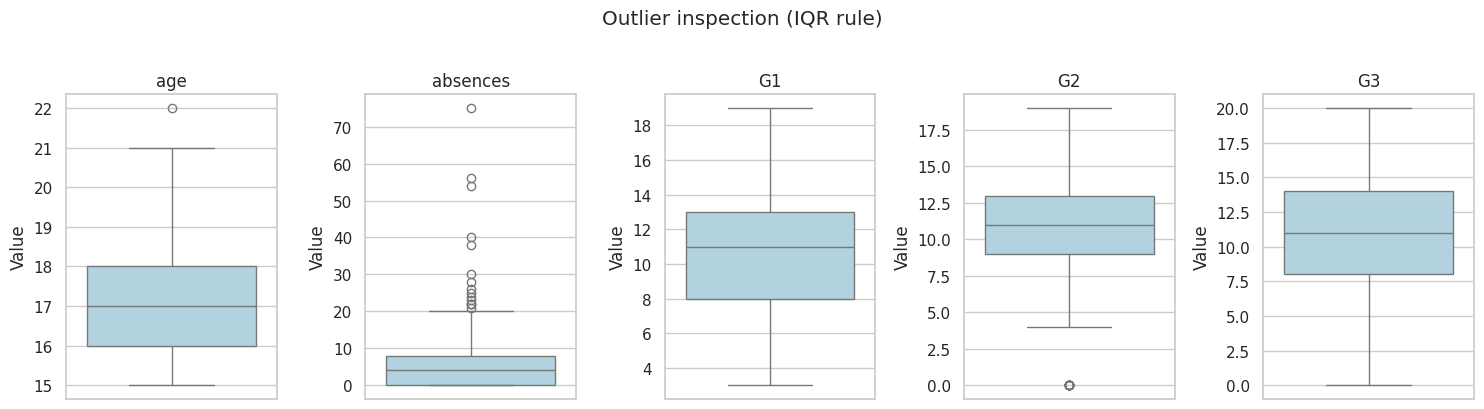

In [7]:
display(dc.outlier_table(raw))
fig = eda.plot_outlier_boxplots(raw, save=False); plt.show()

**Decisions**
- `absences` up to 75 and `age` 22 are plausible real values → **kept**.
- The `G2` "outliers" are zeros. Zeros in `G3` are investigated below in the EDA → **kept**, but flagged.
- Missing values: none, so no imputation is applied here. The modelling pipeline still contains imputers, fitted **only on training data**, so new data with gaps is handled safely.

In [8]:
clean, log = dc.run_cleaning()
summary = pd.DataFrame({"before": log["before"], "after": log["after"]})
display(summary)
print("Cleaned file saved to:", config.PROCESSED_PATH.relative_to(config.ROOT))
df = dc.load_clean()

,before,after
rows,395,395
columns,33,33
missing_values,0,0
duplicate_rows,0,0


Cleaned file saved to: data/processed/student_clean.csv


## Phase 3 — Exploratory data analysis (EDA)
### A. Univariate analysis

,count,mean,median,mode,std,min,max,skew
age,395.0,16.70,17.0,16,1.28,15.0,22.0,0.47
studytime,395.0,2.04,2.0,2,0.84,1.0,4.0,0.63
failures,395.0,0.33,0.0,0,0.74,0.0,3.0,2.39
absences,395.0,5.71,4.0,0,8.00,0.0,75.0,3.67
G1,395.0,10.91,11.0,10,3.32,3.0,19.0,0.24
G2,395.0,10.71,11.0,9,3.76,0.0,19.0,-0.43
G3,395.0,10.42,11.0,10,4.58,0.0,20.0,-0.73


{'mean': np.float64(10.42), 'median': 11.0, 'std': np.float64(4.58), 'min': 0, 'max': 20, 'ci95_low': np.float64(9.96), 'ci95_high': np.float64(10.87), 'pass_rate_G3_ge_10': 67.1, 'zero_grade_count': 38, 'shapiro_p': 8.835916843805374e-13}


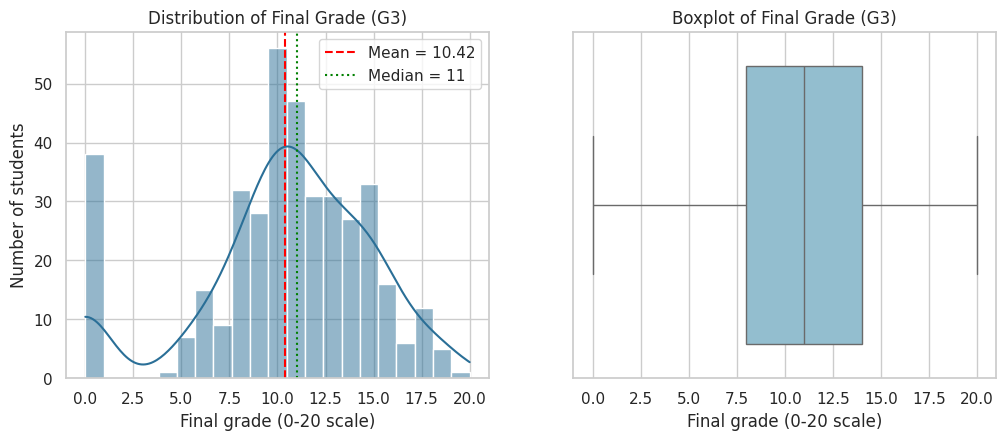

In [9]:
display(eda.descriptive_stats(df))
ts = eda.target_summary(df); print(ts)
fig = eda.plot_target_distribution(df); plt.show()

**Interpretation:** the final-grade distribution is left-skewed with a small spike at 0 (a second mode), so the mean is slightly below the median. The Shapiro–Wilk p-value is tiny → G3 is **not normal**, so we prefer rank-based tests (Spearman, Mann–Whitney, Kruskal–Wallis).

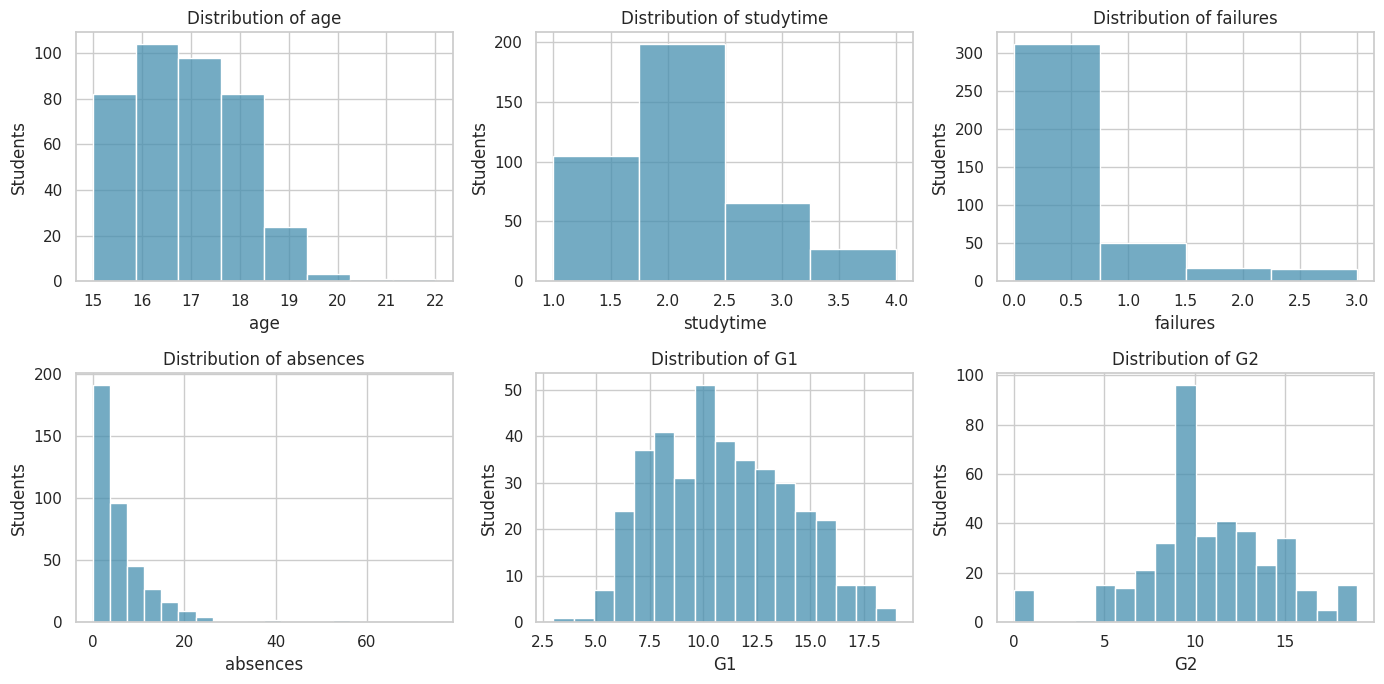

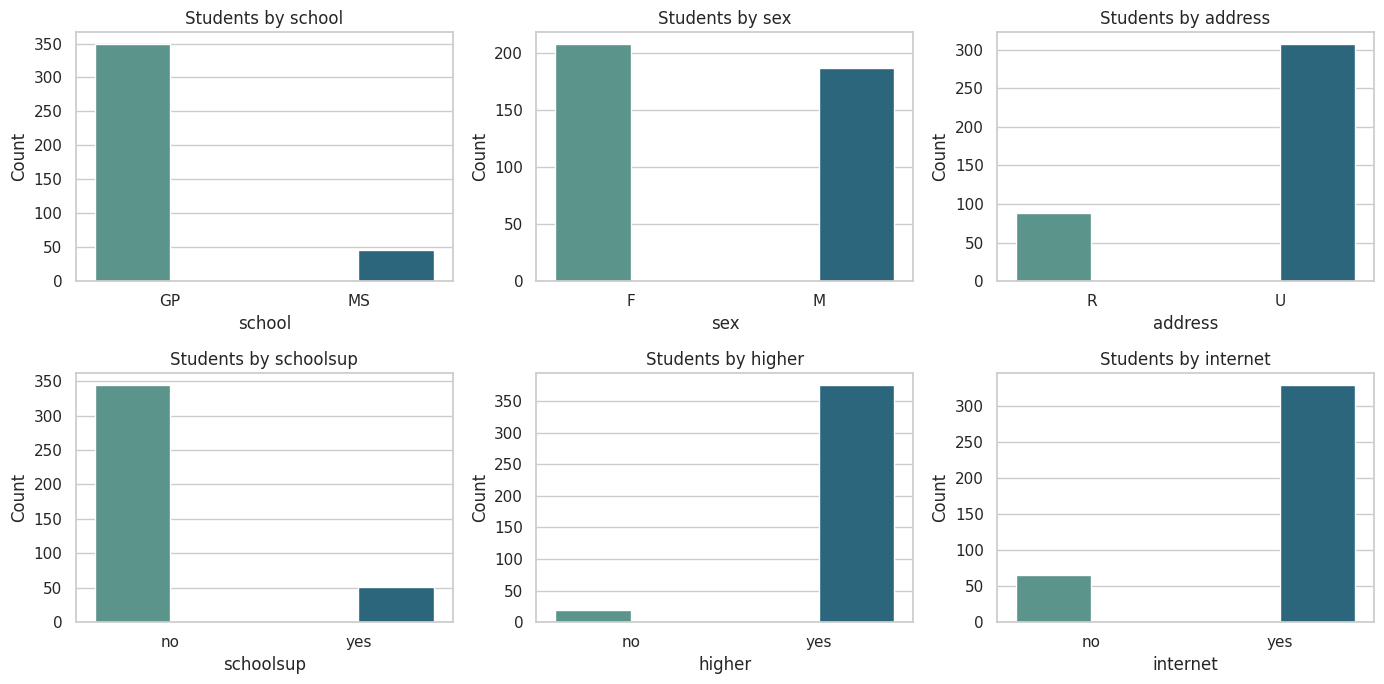

--- school ---
school
GP    349
MS     46

--- sex ---
sex
F    208
M    187

--- higher ---
higher
yes    375
no      20

--- studytime ---
studytime
2    198
1    105
3     65
4     27

--- failures ---
failures
0    312
1     50
2     17
3     16



In [10]:
fig = eda.plot_numeric_histograms(df); plt.show()
fig = eda.plot_categorical_counts(df); plt.show()
for c in ["school", "sex", "higher", "studytime", "failures"]:
    print(f"--- {c} ---"); print(df[c].value_counts().to_string()); print()

### B. Bivariate analysis

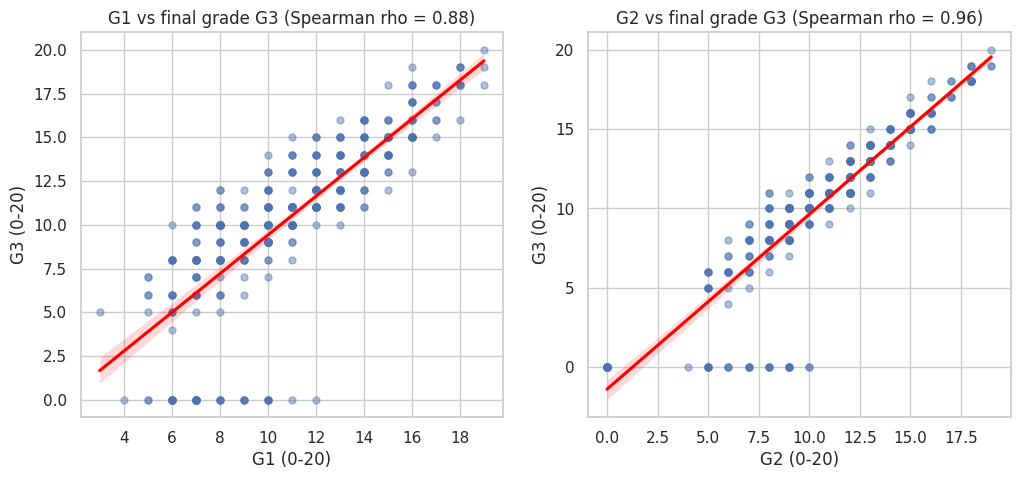

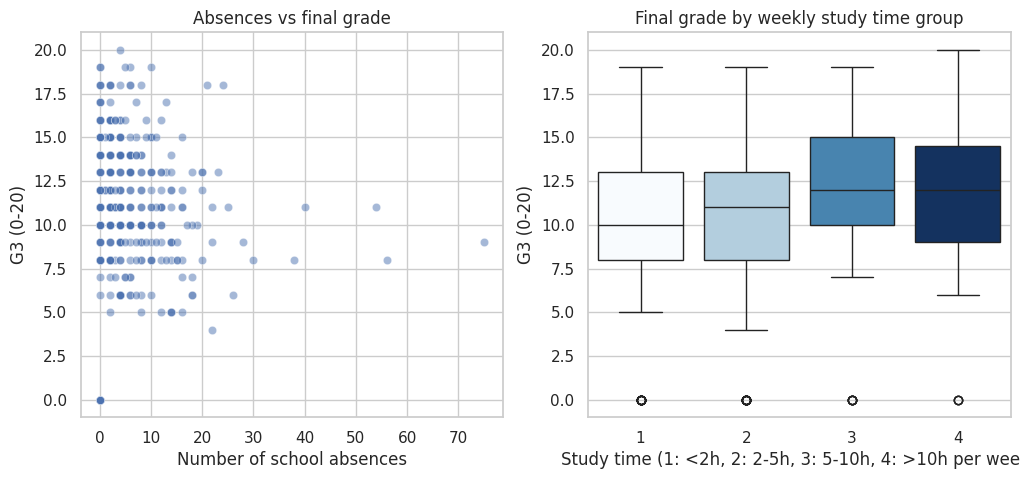

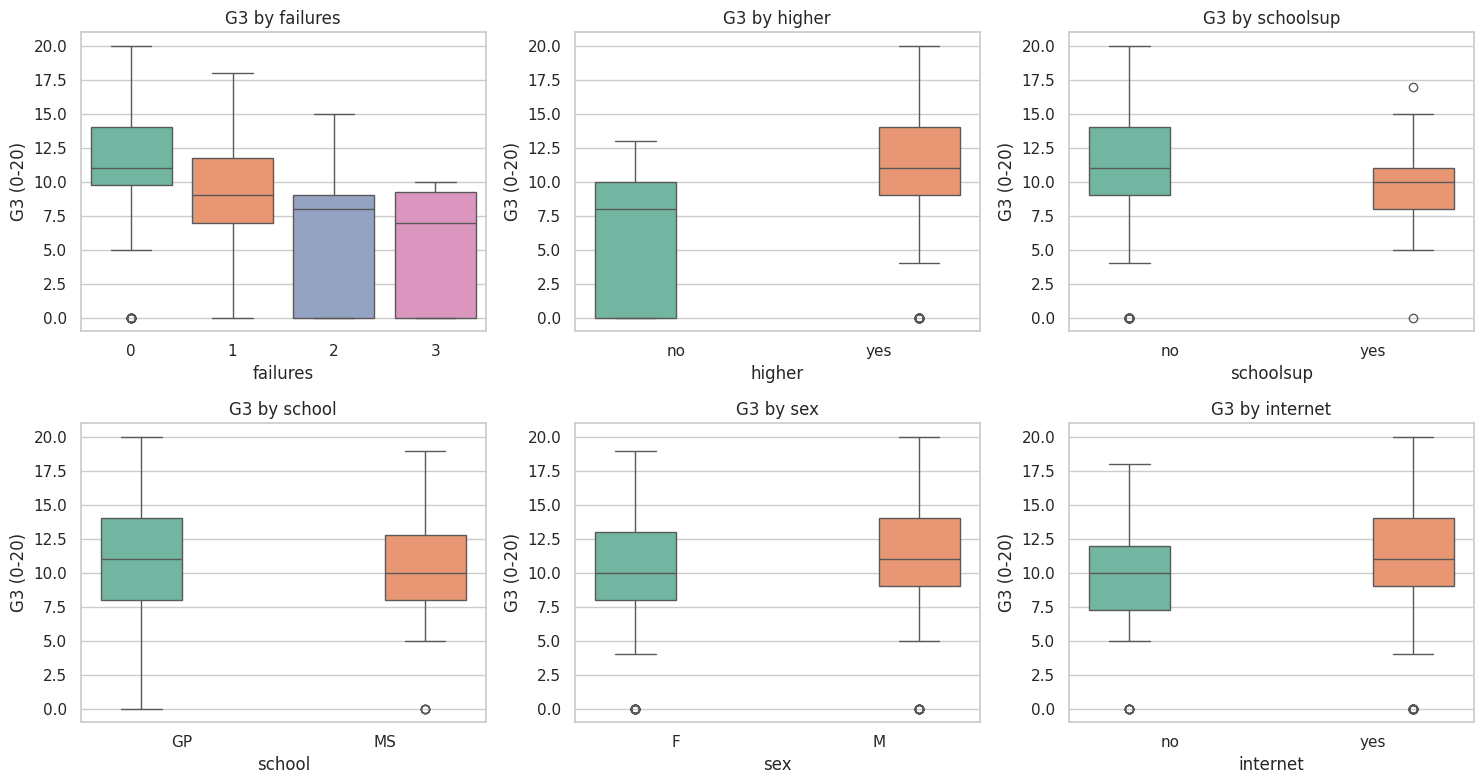

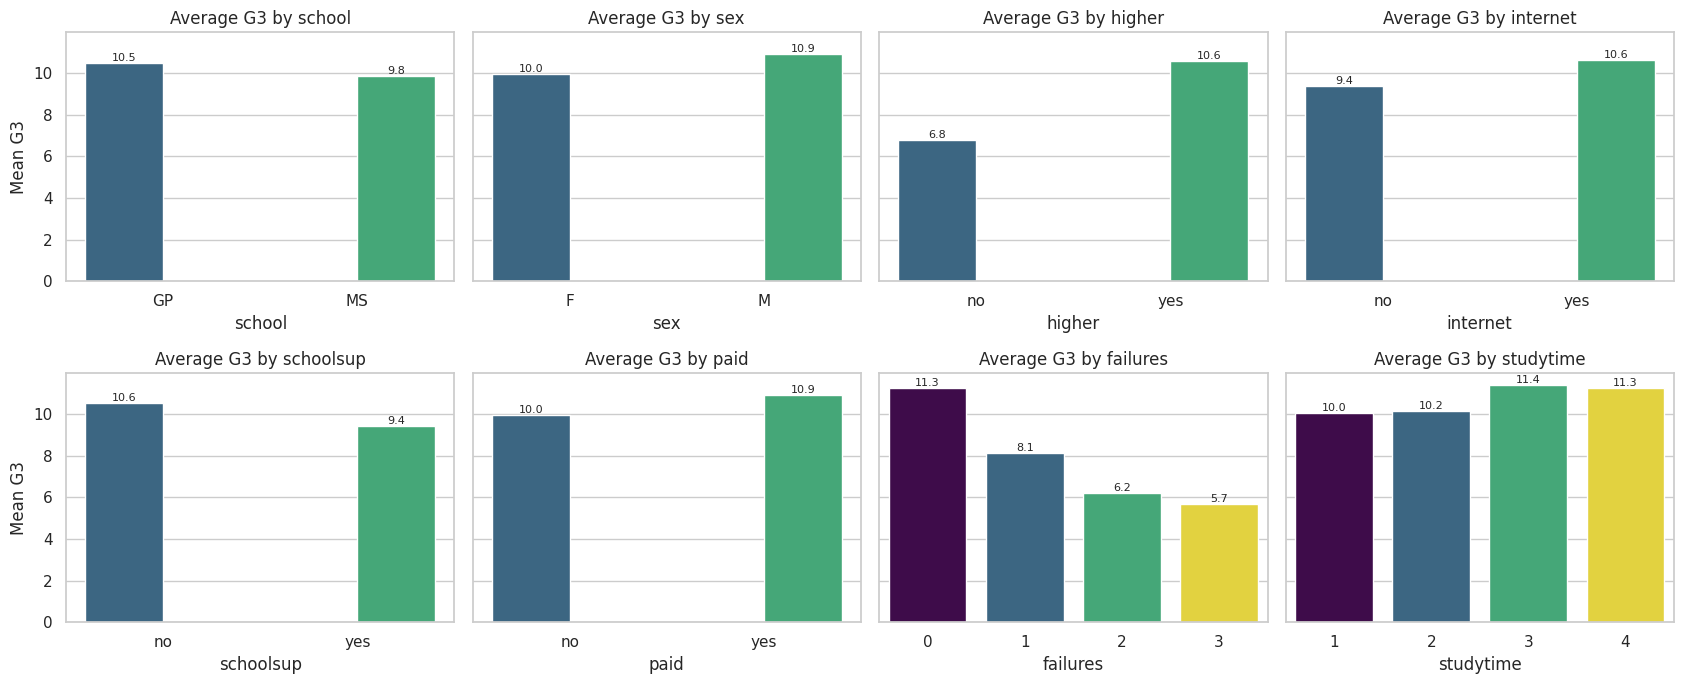

In [11]:
fig = eda.plot_prior_vs_final(df); plt.show()
fig = eda.plot_absences_studytime(df); plt.show()
fig = eda.plot_groups_boxplots(df); plt.show()
fig = eda.plot_mean_bars(df); plt.show()

**Interpretation**
- Earlier grades (`G1`, `G2`) track `G3` very closely → they will dominate any model that uses them.
- Absences show almost no linear relationship with G3 — see the zero-grade check below for why.
- Practical implication: students whose grades fall between periods are the clearest early targets for support.

### C. Multivariate analysis

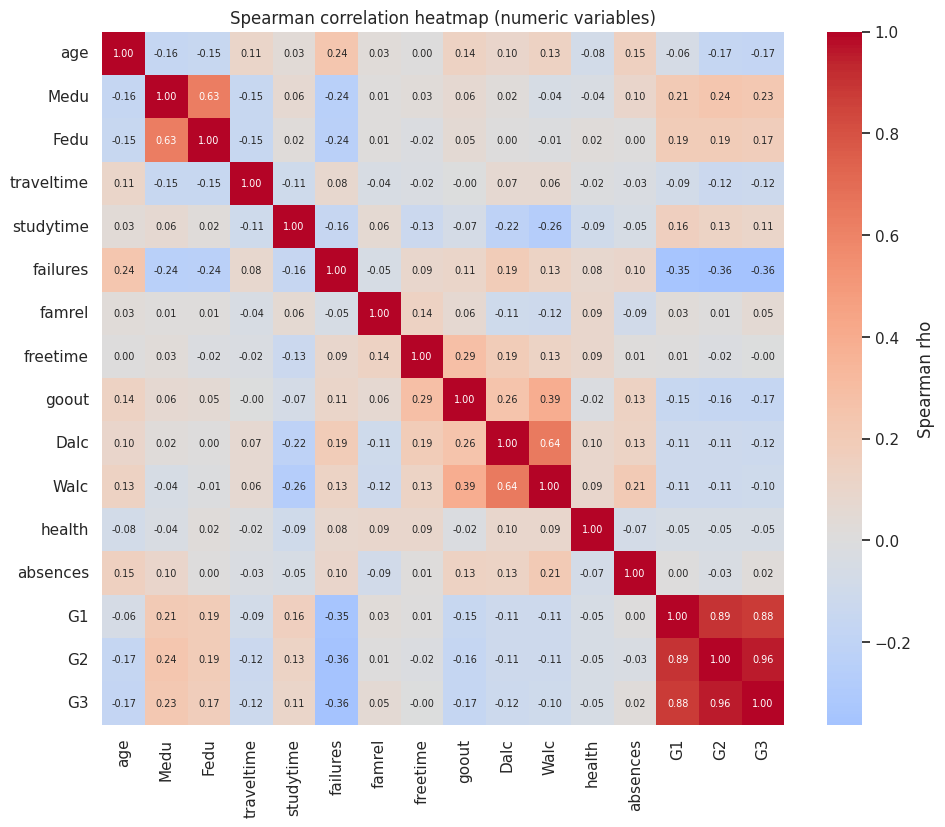

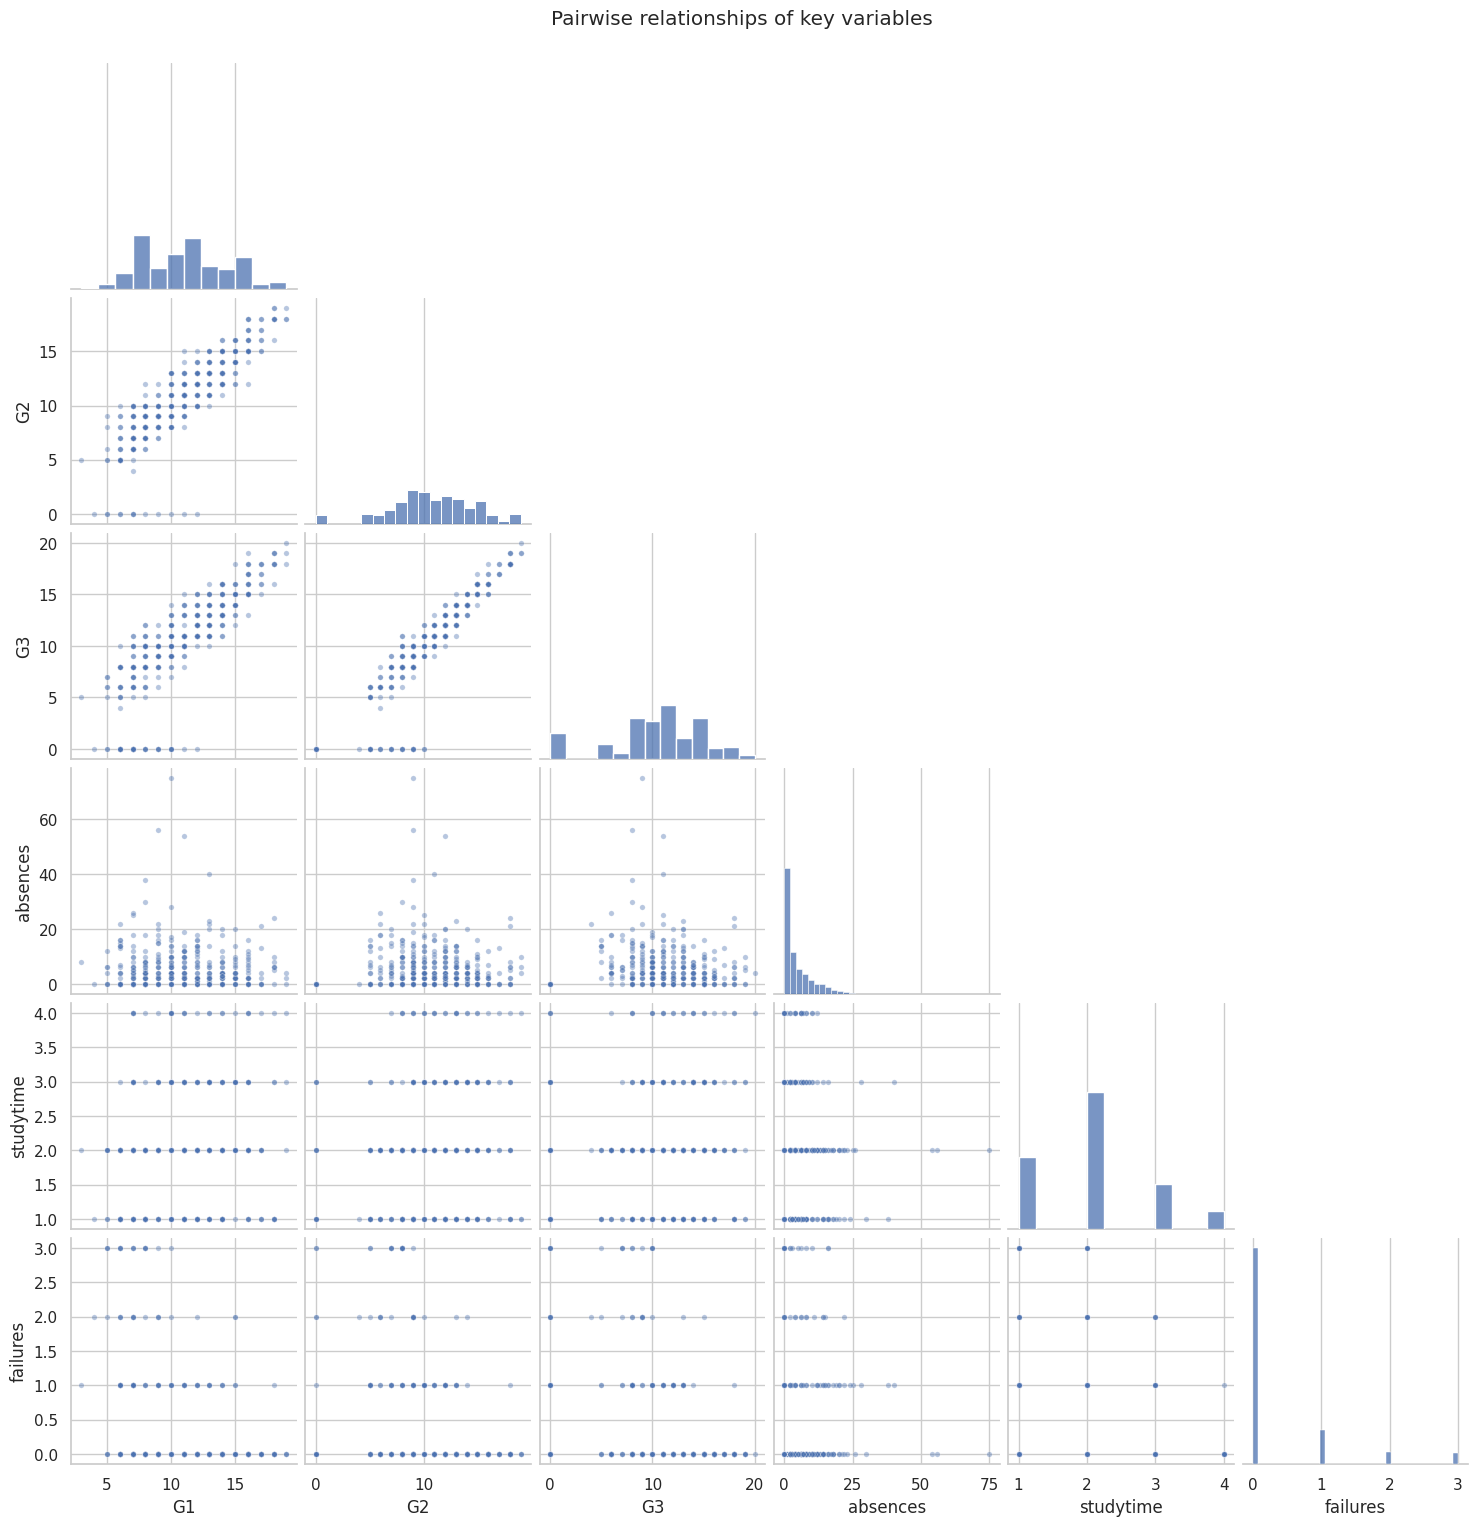

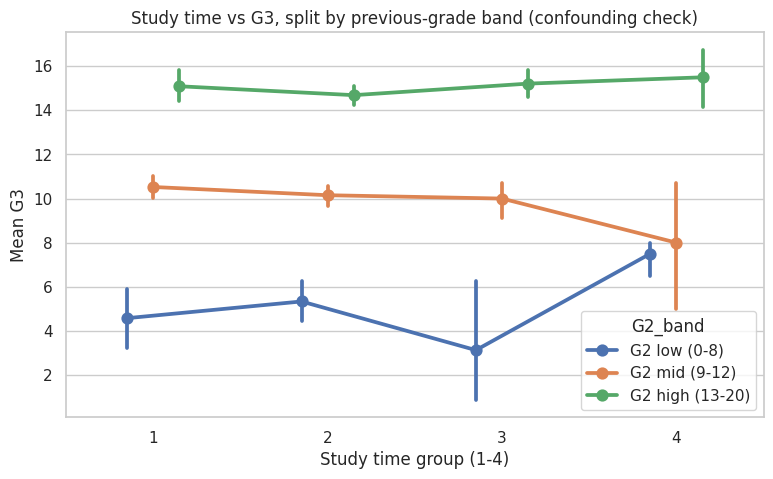

In [12]:
fig = eda.plot_correlation_heatmap(df); plt.show()
fig = eda.plot_pairplot(df); plt.show()
fig = eda.plot_confounding(df); plt.show()

**Confounding check:** study time has only a weak overall association with G3 (Spearman ρ ≈ 0.1). Within each earlier-grade (G2) band the lines are roughly flat, with wide error bars for the small groups, so there is **no clear study-time pattern once prior achievement is held roughly constant**. Study-time categories are also self-reported, which adds noise.

### Investigating students with a final grade of 0

Students with G3 = 0: 38


,G1,G2,absences,failures,studytime
G3 = 0,7.53,4.66,0.00,0.92,1.97
G3 > 0,11.27,11.36,6.32,0.27,2.04


Absences of every G3 = 0 student: [0]


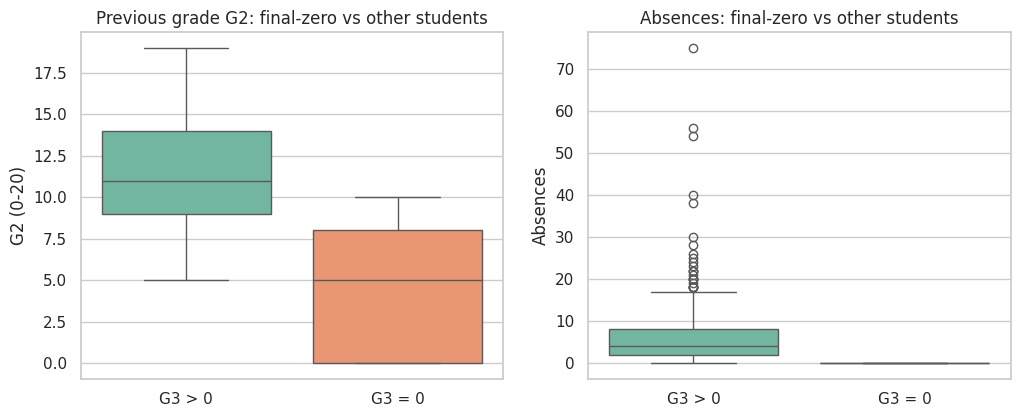

In [13]:
print("Students with G3 = 0:", (df.G3 == 0).sum())
display(eda.zero_grade_profile(df))
print("Absences of every G3 = 0 student:", sorted(df.loc[df.G3 == 0, "absences"].unique().tolist()))
fig = eda.plot_zero_grade_analysis(df); plt.show()

**Data-quality finding:** every student with `G3 = 0` has **0 absences** and a very low `G2`. Zero absences together with a zero final grade is more consistent with students who **left or did not sit the final assessment** than with students who simply scored badly. This is an inference, not a confirmed fact, but it explains why `absences` helps the model despite a near-zero correlation: the effect is non-linear. It also means the model partly learns "who drops out", and such students are hard to predict.

### D. Research questions (every number computed from the data)

In [14]:
corr = eda.correlation_table(df)
print("1. Average final grade:", round(df.G3.mean(), 2), "| median:", df.G3.median())
print("2. Distribution: std =", round(df.G3.std(), 2), "| skew =", round(df.G3.skew(), 2),
      "| pass rate (G3>=10):", f"{(df.G3>=10).mean()*100:.1f}%")
print("\n3. Strongest associations with G3 (Spearman):")
display(corr.head(6)[["feature", "spearman_rho", "p_value", "strength"]])
print("4. Group differences (binary features):")
display(eda.group_comparison_table(df).head(5)[["feature","group_A","group_B","mean_A","mean_B","cohens_d","mannwhitney_p","significant_after_bonferroni"]])
print("5. Useful predictors: earlier grades, failures, parental education, age, going out, absences (non-linear).")
print("6. Data-quality issues: 38 zero final grades (likely dropouts), skewed absences, small groups "
      "(e.g. only 20 students with higher='no'), one-subject/two-school sample.")

1. Average final grade: 10.42 | median: 11.0
2. Distribution: std = 4.58 | skew = -0.73 | pass rate (G3>=10): 67.1%

3. Strongest associations with G3 (Spearman):


,feature,spearman_rho,p_value,strength
0,G2,0.9571,0.0000,strong
1,G1,0.8780,0.0000,strong
2,failures,-0.3612,0.0000,moderate
3,Medu,0.2250,0.0000,weak
4,age,-0.1734,0.0005,weak
5,Fedu,0.1700,0.0007,weak


4. Group differences (binary features):


,feature,group_A,group_B,mean_A,mean_B,cohens_d,mannwhitney_p,significant_after_bonferroni
0,higher,no,yes,6.8000,10.6080,0.8443,0.0006,True
1,schoolsup,no,yes,10.5610,9.4314,-0.2471,0.0028,True
2,address,R,U,9.5114,10.6743,0.2549,0.0178,False
3,internet,no,yes,9.4091,10.6170,0.2646,0.0324,False
4,sex,F,M,9.9663,10.9144,0.2078,0.0407,False


5. Useful predictors: earlier grades, failures, parental education, age, going out, absences (non-linear).
6. Data-quality issues: 38 zero final grades (likely dropouts), skewed absences, small groups (e.g. only 20 students with higher='no'), one-subject/two-school sample.


## Phase 4 — Statistical analysis
- **Spearman** correlation (ranks) because grades are bounded/ordinal and G3 is non-normal.
- **Mann–Whitney U** for two groups, **Kruskal–Wallis** for 3+ groups (no normality needed).
- **Effect sizes** (Cohen's d, epsilon²) show *practical* importance; p-values only show *statistical* evidence. With many tests, some "significant" results appear by chance, so a Bonferroni-adjusted flag is included.
- All results are observational → no causal claims.

In [15]:
lo, hi = ts["ci95_low"], ts["ci95_high"]
print(f"Mean G3 = {ts['mean']}  (95% confidence interval {lo} to {hi}, t-based)")
print("Normality of G3 (Shapiro-Wilk) p =", f"{ts['shapiro_p']:.2e}", "-> not normal, so rank-based tests are used")
print("\nSpearman correlations with G3:"); display(corr)
print("Binary group comparisons:"); display(eda.group_comparison_table(df))
print("Multi-level groups:"); display(eda.multi_group_tests(df))

Mean G3 = 10.42  (95% confidence interval 9.96 to 10.87, t-based)
Normality of G3 (Shapiro-Wilk) p = 8.84e-13 -> not normal, so rank-based tests are used

Spearman correlations with G3:


,feature,spearman_rho,p_value,pearson_r,strength
0,G2,0.9571,0.0000,0.9049,strong
1,G1,0.8780,0.0000,0.8015,strong
2,failures,-0.3612,0.0000,-0.3604,moderate
3,Medu,0.2250,0.0000,0.2171,weak
4,age,-0.1734,0.0005,-0.1616,weak
5,Fedu,0.1700,0.0007,0.1525,weak
6,goout,-0.1661,0.0009,-0.1328,weak
7,Dalc,-0.1209,0.0162,-0.0547,weak
8,traveltime,-0.1205,0.0165,-0.1171,weak
9,studytime,0.1052,0.0367,0.0978,weak


Binary group comparisons:


,feature,group_A,group_B,n_A,n_B,mean_A,mean_B,mean_diff_(B-A),cohens_d,mannwhitney_p,significant_p<0.05,significant_after_bonferroni
0,higher,no,yes,20,375,6.8000,10.6080,3.8080,0.8443,0.0006,True,True
1,schoolsup,no,yes,344,51,10.5610,9.4314,-1.1297,-0.2471,0.0028,True,True
2,address,R,U,88,307,9.5114,10.6743,1.1629,0.2549,0.0178,True,False
3,internet,no,yes,66,329,9.4091,10.6170,1.2079,0.2646,0.0324,True,False
4,sex,F,M,208,187,9.9663,10.9144,0.9481,0.2078,0.0407,True,False
5,romantic,no,yes,263,132,10.8365,9.5758,-1.2607,-0.2772,0.0695,False,False
6,famsize,GT3,LE3,281,114,10.1779,11.0000,0.8221,0.1798,0.1885,False,False
7,school,GP,MS,349,46,10.4900,9.8478,-0.6421,-0.1401,0.2002,False,False
8,paid,no,yes,214,181,9.9860,10.9227,0.9367,0.2053,0.2267,False,False
9,famsup,no,yes,153,242,10.6405,10.2727,-0.3678,-0.0802,0.3165,False,False


Multi-level groups:


,feature,groups,H,p_value,epsilon_squared
0,failures,4,53.1151,0.0000,0.1282
1,Medu,4,23.0782,0.0000,0.0514
2,Fedu,4,14.0610,0.0028,0.0283
3,Mjob,5,16.1274,0.0029,0.0311
4,studytime,4,7.5789,0.0556,0.0117
5,traveltime,4,6.1374,0.1051,0.0080
6,guardian,3,3.8131,0.1486,0.0046
7,Fjob,5,6.2764,0.1794,0.0058
8,reason,4,4.8664,0.1818,0.0048


**Reading the tables**
- |ρ| < 0.1 negligible, 0.1–0.3 weak, 0.3–0.5 moderate, > 0.5 strong.
- `failures` is the strongest non-grade feature (moderate, negative); parental education is weak-positive.
- `higher = no` has the largest gap, but only 20 students are in that group → treat it with care.
- Sex, address and internet differences are small (d ≈ 0.2) and do not survive the Bonferroni check.

## Phase 5 — Feature engineering and leakage checks
Two scenarios answer two different real questions:

| Scenario | Inputs | Use |
|---|---|---|
| **A – with earlier grades** | habits + background + `G1`, `G2`, `grade_trend` | mid-year estimate |
| **B – early warning** | habits + background only | very early estimate, no grades yet |

- `grade_trend = G2 − G1` (positive = improving).
- `G3` is never an input (no leakage); B excludes `G1`/`G2` so it is a fair "no-grades" test.
- **Excluded for fairness:** `sex`, `address`, `famsize`, `Pstatus`, `Mjob`, `Fjob`, `guardian`, `romantic`, `nursery`, `reason` — predictions should not penalise students for family or personal circumstances.
- 80/20 train–test split with `random_state=42`.

In [16]:
for name, spec in config.SCENARIOS.items():
    feats = spec["numeric"] + spec["categorical"]
    assert config.TARGET not in feats
    print(f"{name}: {len(feats)} features ->", feats, "\n")
print("Leakage check passed: G3 is not used as an input.")

with_prior_grades: 23 features -> ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'grade_trend', 'school', 'schoolsup', 'famsup', 'paid', 'activities', 'higher', 'internet'] 


Leakage check passed: G3 is not used as an input.


## Phase 6 — Machine learning
**Models compared (same split, same CV folds):** Dummy baseline, Linear Regression, Random Forest, Gradient Boosting.
- Everything (imputer, scaler, one-hot encoder, model) lives in one scikit-learn **Pipeline** → fitted on training folds only.
- Random Forest and Gradient Boosting are tuned with `GridSearchCV` (5-fold) on the **training set only**.
- The final model is **chosen by cross-validation RMSE**; the **test set is evaluated once afterwards**.
- Metrics: **MAE** (average error in grade points), **RMSE** (penalises big misses), **R²** (share of variance explained; ≤ 0 means no better than predicting the mean).

In [17]:
results = {name: tm.train_scenario(df, name) for name in config.SCENARIOS}
config.METRICS_PATH.write_text(__import__("json").dumps(results, indent=2, default=float))
tm.plot_model_results(results)
for name, res in results.items():
    print(f"\n===== Scenario {name}  (train={res['n_train']}, test={res['n_test']}) =====")
    display(pd.DataFrame(res["comparison"]).drop(columns="best_params").round(3))
    print("Selected (lowest CV RMSE):", res["best_model"])
    print("Test metrics of selected model:", {k: round(v, 3) for k, v in res["test_metrics_best"].items()})


===== Scenario with_prior_grades  (train=316, test=79) =====


,model,cv_MAE,cv_RMSE,cv_R2,test_MAE,test_RMSE,test_R2
0,Dummy (mean baseline),3.403,4.564,-0.035,3.646,4.550,-0.010
1,Linear Regression,1.285,1.884,0.824,1.440,2.191,0.766
2,Random Forest,0.976,1.586,0.876,1.043,1.690,0.861
3,Gradient Boosting,0.968,1.579,0.876,1.057,1.764,0.848


Selected (lowest CV RMSE): Gradient Boosting
Test metrics of selected model: {'MAE': 1.057, 'RMSE': 1.764, 'R2': 0.848}

===== Scenario early_warning  (train=316, test=79) =====


,model,cv_MAE,cv_RMSE,cv_R2,test_MAE,test_RMSE,test_R2
0,Dummy (mean baseline),3.403,4.564,-0.035,3.646,4.550,-0.010
1,Linear Regression,3.361,4.394,0.018,3.716,4.442,0.038
2,Random Forest,2.960,3.938,0.203,3.273,3.968,0.232
3,Gradient Boosting,3.068,3.984,0.199,3.428,4.186,0.146


Selected (lowest CV RMSE): Random Forest
Test metrics of selected model: {'MAE': 3.273, 'RMSE': 3.968, 'R2': 0.232}


**Interpretation**
- **Scenario A:** both tree ensembles cut the baseline error by well over half (CV RMSE about 1.6 vs 4.6). Random Forest and Gradient Boosting are nearly tied in cross-validation, so the choice between them is not clear-cut; the test set has only 79 students, so its numbers carry real uncertainty.
- **Scenario B:** without grades the model is only modestly better than the baseline (R² well below 0.3). Habits and background alone are weak predictors here — this is an honest limitation, not a bug.
- Linear Regression is a reasonable but weaker model than the ensembles in Scenario A.

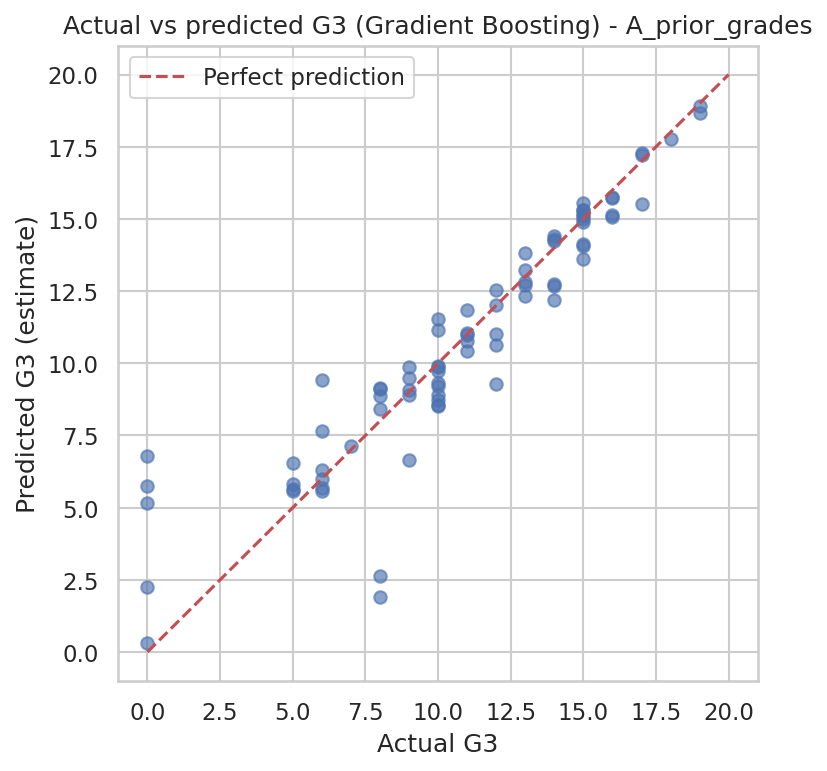

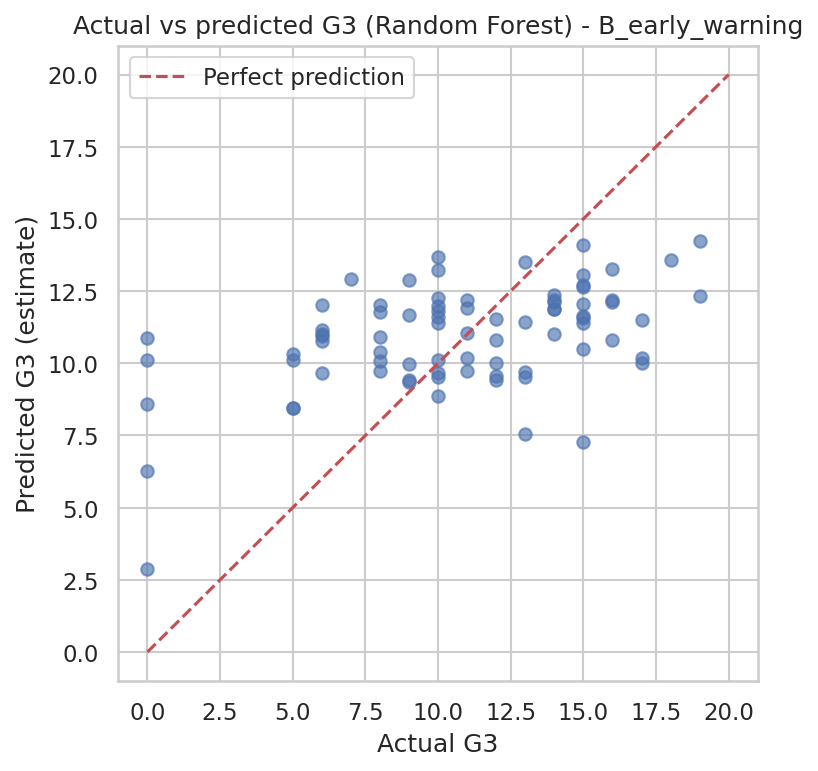

In [18]:
from IPython.display import Image
for tag in ["A_prior_grades", "B_early_warning"]:
    display(Image(str(config.VIZ_DIR / f"14_actual_vs_predicted_{tag}.png"), width=380))

### Feature importance (permutation importance, test set)

with_prior_grades


,feature,importance_mean,importance_std
0,G2,3.7690,0.3072
1,absences,0.7071,0.1711
2,G1,0.1510,0.0475
3,famrel,0.0286,0.0221
4,age,0.0280,0.0325
5,activities,0.0158,0.0157
6,Fedu,0.0050,0.0070
7,Walc,0.0034,0.0027


early_warning


,feature,importance_mean,importance_std
0,failures,0.5829,0.1753
1,absences,0.4915,0.1849
2,goout,0.2331,0.0975
3,age,0.1070,0.0838
4,schoolsup,0.0932,0.0368
5,Medu,0.0757,0.0388
6,famrel,0.0386,0.0304
7,freetime,0.0334,0.0256


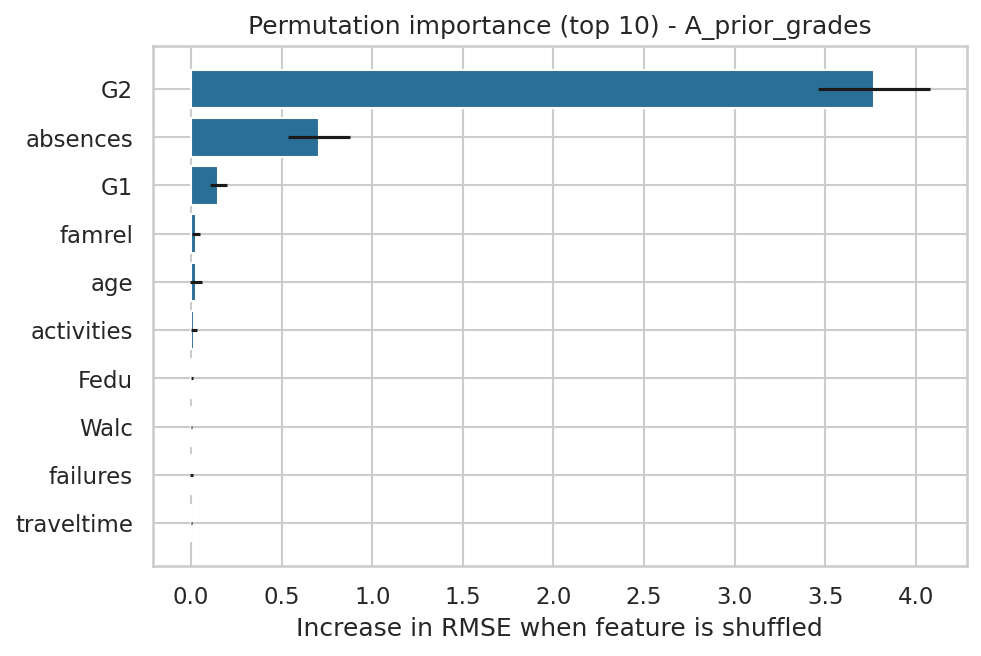

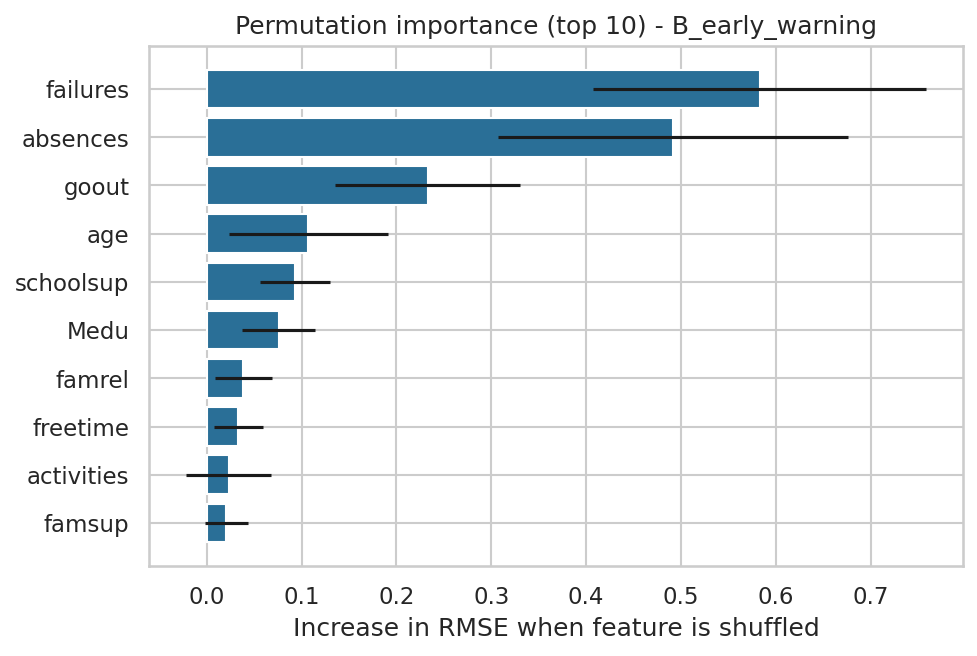

In [19]:
for name, res in results.items():
    print(name); display(pd.DataFrame(res["importance"]).head(8))
for tag in ["A_prior_grades", "B_early_warning"]:
    display(Image(str(config.VIZ_DIR / f"15_feature_importance_{tag}.png"), width=520))

**Caution:** importance = how much *predictions* worsen when a feature is shuffled. It does **not** show that changing the feature would change a student's grade.

## Phase 7 — Prediction function
`predict_score()` validates the input, applies the **saved** pipeline (no retraining) and returns an *estimate* between 0 and 20. Bad input returns a clear message instead of crashing.

In [20]:
student = pr.SAMPLE_STUDENT
print(pr.predict_score(student)["message"])
early = {k: v for k, v in student.items() if k not in ("G1", "G2")}
print(pr.predict_score(early, scenario="early_warning")["message"])
print()
print("Invalid grade  ->", pr.predict_score({**student, "G2": 55})["message"])
print("Invalid label  ->", pr.predict_score({**student, "school": "XX"})["message"])
print("Missing field  ->", pr.predict_score({k: v for k, v in student.items() if k != "absences"})["message"])

Estimated final grade (G3): 10.9 / 20. This is an estimate, not a guaranteed outcome.
Estimated final grade (G3): 10.7 / 20. This is an estimate, not a guaranteed outcome.

Invalid grade  -> Invalid input: G2: 55 is outside the valid range 0-20
Invalid label  -> Invalid input: school: 'XX' not in ['GP', 'MS']
Missing field  -> Invalid input: Missing required field: absences


## Phase 8 — Dashboard
The Streamlit dashboard is in `dashboard/app.py`. From the repository root run:
```
streamlit run dashboard/app.py
```
Pages: Overview · Data Explorer · Visual Analytics · Statistical Insights · Model Performance · Predict a Score.

## Limitations, ethics and future work
**Limitations**
- Only 395 students, two schools, one subject → results may not generalise.
- The test set has 79 students, so metrics are uncertain; model differences of a few hundredths are not meaningful.
- No attendance-percentage or exact study-hours data; `studytime` is a 4-level group.
- Likely dropouts (G3 = 0) are hard to predict and affect every metric.
- Scenario A is dominated by `G2` — it mostly says "the final grade will resemble the last grade".

**Ethics**
- Predictions are estimates for starting supportive conversations, never for labelling, grouping or penalising students.
- Sensitive and family attributes were deliberately excluded from the models.
- Associations (and importance scores) are not causes.

**Future work**
- Repeated cross-validation or more data for tighter estimates; compare with a dropout-vs-grade two-stage model.
- Fairness audit of errors across student groups; calibration / prediction intervals.
- Combine with the Portuguese-language dataset and add real attendance data.

**Conclusion:** the project covers the full workflow — data → cleaning → EDA → statistics → models → prediction → dashboard — and reports weaknesses openly.